# Play Store App Review Analysis

## 1. Introduction

### Business Context

The Google Play Store contains a large collection of Android applications
with information such as category, ratings, reviews, size, installs,
pricing, content rating and other attributes.

The objective of this project is to explore the Play Store application
data along with user review data to identify factors associated with
app engagement and success and derive actionable insights for app developers.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Upload the datasets to Colab

In [ ]:
play_store = pd.read_csv("/content/Play Store Data.csv")
user_reviews = pd.read_csv("/content/User Reviews.csv")

Verify that the datasets loaded correctly

In [ ]:
print("Play store dataset shape: ", play_store.shape)
print("User reviews dataset shape: ", user_reviews.shape)

Play store dataset shape:  (10841, 13)
User reviews dataset shape:  (17155, 5)


Top 5 data of the Play store

In [ ]:
play_store.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


Top 5 data of the User reviews

In [ ]:
user_reviews.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


Bottom 5 data of the Play store

In [ ]:
play_store.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


Bottom 5 data of the User reviews

In [ ]:
user_reviews.tail()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
17150,Bowmasters,"ADS everywhere! Before match, claiming chests,...",Negative,-0.7000,0.700
17151,Bowmasters,Screen freezes sometimes slows making accuracy...,Positive,0.0500,0.700
17152,Bowmasters,It great game laggy. That's problem.,Positive,0.2000,0.575
17153,Bowmasters,Pretty good game Loved it!Great time killer I'...,Positive,0.3125,0.700
17154,Bowmasters,Love every thing I want chest I ra,NaN,NaN,NaN


Columns and data types of it

In [ ]:
play_store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [ ]:
user_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17155 entries, 0 to 17154
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     17155 non-null  object 
 1   Translated_Review       10945 non-null  object 
 2   Sentiment               10946 non-null  object 
 3   Sentiment_Polarity      10946 non-null  float64
 4   Sentiment_Subjectivity  10946 non-null  float64
dtypes: float64(2), object(3)
memory usage: 670.2+ KB


Check duplicate records

In [ ]:
print("Play store duplicates: ", play_store.duplicated().sum())
print("User reviews duplicates: ", user_reviews.duplicated().sum())

Play store duplicates:  483
User reviews duplicates:  7980


Check missing values

In [ ]:
play_store.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


In [ ]:
user_reviews.isnull().sum()

,0
App,0
Translated_Review,6210
Sentiment,6209
Sentiment_Polarity,6209
Sentiment_Subjectivity,6209


Numerical summary of data

In [ ]:
play_store.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [ ]:
user_reviews.describe()

,Sentiment_Polarity,Sentiment_Subjectivity
count,10946.000000,10946.000000
mean,0.172173,0.487589
std,0.359112,0.265377
min,-1.000000,0.000000
25%,0.000000,0.340000
50%,0.136364,0.512500
75%,0.400000,0.650000
max,1.000000,1.000000


## 5. Data Cleaning

### 5.1 Checking Duplicate Records

Duplicate records can affect aggregation and visualization by giving
excessive weight to repeated observations. Therefore, duplicate records
will be investigated before deciding how to handle them.

In [ ]:
play_store[play_store.duplicated()].head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,"5,000,000+",Free,0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,"10,000,000+",Free,0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,"5,000,000+",Free,0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,"10,000,000+",Free,0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,"1,000,000+",Free,0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up


In [ ]:
play_store[play_store.duplicated()].shape

(483, 13)

In [ ]:
play_store["App"].duplicated().sum()

np.int64(1181)

In [ ]:
play_store["App"].value_counts().head(20)

,count
App,
ROBLOX,9
"CBS Sports App - Scores, News, Stats & Watch Live",8
8 Ball Pool,7
Candy Crush Saga,7
ESPN,7
Duolingo: Learn Languages Free,7
Temple Run 2,6
Bowmasters,6
Helix Jump,6


Why?

Because:

duplicate ROW ≠ duplicate APP

An app can legitimately appear more than once in the raw dataset.

We need to understand whether those repeated app names represent:

true duplicates
different versions/records
inconsistent records
data collection issues

In [ ]:
play_store["Rating"].isnull().sum()

np.int64(1474)

In [ ]:
rating_missing_percentage = play_store["Rating"].isnull().mean()*100
rating_missing_percentage

np.float64(13.596531685268886)

Investigate missing values in Play Store

In [ ]:
missing_play_store = pd.DataFrame({
    "Missing Values" : play_store.isnull().sum(),
    "Missing Percentage" : (play_store.isnull().mean()*100).round(2)
})

missing_play_store.sort_values(
    by = "Missing Values",
    ascending = False
)


,Missing Values,Missing Percentage
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01
Size,0,0.00
Reviews,0,0.00
Category,0,0.00
App,0,0.00
Price,0,0.00


Investigate missing values in User Reviews

In [ ]:
missing_reviews = pd.DataFrame({
    "Missing Values" : user_reviews.isnull().sum(),
    "Missing Percentage" : (user_reviews.isnull().mean()*100).round(2)
})

missing_reviews.sort_values(
    by = "Missing Values",
    ascending= False
)

,Missing Values,Missing Percentage
Translated_Review,6210,36.20
Sentiment_Polarity,6209,36.19
Sentiment,6209,36.19
Sentiment_Subjectivity,6209,36.19
App,0,0.00


Understand the strange data types

In [ ]:
print(play_store["Reviews"].head(10).tolist())
print(play_store["Size"].head(10).tolist())
print(play_store["Installs"].head(10).tolist())
print(play_store["Price"].head(10).tolist())
print(play_store["Last Updated"].head(10).tolist())

['159', '967', '87510', '215644', '967', '167', '178', '36815', '13791', '121']
['19M', '14M', '8.7M', '25M', '2.8M', '5.6M', '19M', '29M', '33M', '3.1M']
['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+', '50,000+', '50,000+', '1,000,000+', '1,000,000+', '10,000+']
['0', '0', '0', '0', '0', '0', '0', '0', '0', '0']
['January 7, 2018', 'January 15, 2018', 'August 1, 2018', 'June 8, 2018', 'June 20, 2018', 'March 26, 2017', 'April 26, 2018', 'June 14, 2018', 'September 20, 2017', 'July 3, 2018']


check unique values for the problematic columns

In [ ]:
print(play_store["Size"].unique()[:20])

['19M' '14M' '8.7M' '25M' '2.8M' '5.6M' '29M' '33M' '3.1M' '28M' '12M'
 '20M' '21M' '37M' '2.7M' '5.5M' '17M' '39M' '31M' '4.2M']


In [ ]:
print(play_store["Installs"].unique()[:20])

['10,000+' '500,000+' '5,000,000+' '50,000,000+' '100,000+' '50,000+'
 '1,000,000+' '10,000,000+' '5,000+' '100,000,000+' '1,000,000,000+'
 '1,000+' '500,000,000+' '50+' '100+' '500+' '10+' '1+' '5+' '0+']


In [ ]:
print(play_store["Price"].unique()[:20])

['0' '$4.99' '$3.99' '$6.99' '$1.49' '$2.99' '$7.99' '$5.99' '$3.49'
 '$1.99' '$9.99' '$7.49' '$0.99' '$9.00' '$5.49' '$10.00' '$24.99'
 '$11.99' '$79.99' '$16.99']


Data Cleaning

In [ ]:
play_store[play_store.duplicated()].head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,"5,000,000+",Free,0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,"10,000,000+",Free,0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,"5,000,000+",Free,0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,"10,000,000+",Free,0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,"1,000,000+",Free,0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up


In [ ]:
play_store[play_store.duplicated()].shape

(483, 13)

In [ ]:
play_store["App"].duplicated().sum()

np.int64(1181)

In [ ]:
play_store["App"].value_counts().head()

,count
App,
ROBLOX,9
"CBS Sports App - Scores, News, Stats & Watch Live",8
8 Ball Pool,7
Candy Crush Saga,7
ESPN,7


## 5. Data Cleaning

### 5.1 Missing Value Analysis

Missing values can affect the accuracy of analysis and visualization.
Therefore, we first identify the number and percentage of missing values
in each column before deciding how to handle them.

In [ ]:
missing_play_store = pd.DataFrame({
    'Missing Values': play_store.isnull().sum(),
    'Missing Percentage': (play_store.isnull().mean() * 100).round(2)
})

missing_play_store.sort_values(
    by='Missing Values',
    ascending=False
)

,Missing Values,Missing Percentage
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01
Size,0,0.00
Reviews,0,0.00
Category,0,0.00
App,0,0.00
Price,0,0.00


### Missing Value Treatment

- **Rating:** Missing values were retained because 13.60% of the values are missing. Since rating is an important analytical variable, imputing arbitrary values could distort the distribution and lead to misleading conclusions.
- **Current Ver, Android Ver, Content Rating, and Type:** The number of missing values is extremely small, so these missing categorical values will be replaced with `"Unknown"` to retain the corresponding records without introducing fabricated information.

In [ ]:
categorical_missing_cols = [
    "Current Ver",
    "Android Ver",
    "Content Rating",
    "Type"
]

for col in categorical_missing_cols:
  play_store[col] = play_store[col].fillna("Unknown")

Verify the cleaning

In [ ]:
play_store.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,0
Genres,0


### 5.2 Handling Duplicate Records

The Play Store dataset initially contained 483 exact duplicate rows.
These records were removed because they contained identical information
across all columns and could give disproportionate weight to repeated
observations during analysis.

Duplicate App names were not removed because repeated App names do not
necessarily represent identical records.

In [ ]:
print("Rows before removing duplicates: ", play_store.shape[0])

Rows before removing duplicates:  10841


In [ ]:
play_store = play_store.drop_duplicates()

In [ ]:
print("Rows before removing duplicates: ", play_store.shape[0])
print("Duplicates rows remaining: ", play_store.duplicated().sum())

Rows before removing duplicates:  10358
Duplicates rows remaining:  0


### 5.3 Data Type Cleaning

Several columns are stored as object data types even though they represent
numerical or date-based information. These columns need to be inspected
and transformed into appropriate formats before performing further analysis.

In [ ]:
print("Reviews: ")
print(play_store["Reviews"].head(10).tolist())

print("\n Size: ")
print(play_store["Size"].head(10).tolist())

print("\n Installs: ")
print(play_store["Installs"].head(10).tolist())

print("\n Price: ")
print(play_store["Price"].head(10).tolist())

print("\n Last Updated: ")
print(play_store["Last Updated"].head(10).tolist())

Reviews: 
['159', '967', '87510', '215644', '967', '167', '178', '36815', '13791', '121']

 Size: 
['19M', '14M', '8.7M', '25M', '2.8M', '5.6M', '19M', '29M', '33M', '3.1M']

 Installs: 
['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+', '50,000+', '50,000+', '1,000,000+', '1,000,000+', '10,000+']

 Price: 
['0', '0', '0', '0', '0', '0', '0', '0', '0', '0']

 Last Updated: 
['January 7, 2018', 'January 15, 2018', 'August 1, 2018', 'June 8, 2018', 'June 20, 2018', 'March 26, 2017', 'April 26, 2018', 'June 14, 2018', 'September 20, 2017', 'July 3, 2018']


Clean Reviews

In [ ]:
play_store['Reviews'] = play_store['Reviews'].astype(str).str.replace('M', 'e6').str.replace('K', 'e3').str.replace('+', '', regex=False).str.replace(',', '', regex=False)
play_store['Reviews'] = pd.to_numeric(play_store['Reviews'], errors='coerce')

In [ ]:
print(play_store['Reviews'].dtype)

float64


In [ ]:
play_store['Reviews'].head(10)

,Reviews
0,159.0
1,967.0
2,87510.0
3,215644.0
4,967.0
5,167.0
6,178.0
7,36815.0
8,13791.0
9,121.0


Reviews was stored as an object/string even though it represented numerical counts. I converted it to a numeric data type so that statistical calculations and aggregations could be performed correctly

Installs contained commas and a plus sign because the original dataset represented installation counts in a user-friendly format. I removed these formatting characters and converted the column to an integer so that numerical analysis could be performed

In [ ]:
play_store['Installs'] = (
    play_store['Installs']
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)
play_store['Installs'] = pd.to_numeric(play_store['Installs'], errors='coerce')

In [ ]:
print(play_store['Installs'].dtype)

float64


In [ ]:
play_store['Installs'].head(10)

,Installs
0,10000.0
1,500000.0
2,5000000.0
3,50000000.0
4,100000.0
5,50000.0
6,50000.0
7,1000000.0
8,1000000.0
9,10000.0


Clean Price

In [ ]:
play_store["Price"].unique()[:20]

array(['0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99', '$7.99', '$5.99',
       '$3.49', '$1.99', '$9.99', '$7.49', '$0.99', '$9.00', '$5.49',
       '$10.00', '$24.99', '$11.99', '$79.99', '$16.99'], dtype=object)

In [ ]:
play_store["Price"] = (
    play_store["Price"]
    .str.replace("$","",regex=False)
)
play_store["Price"] = pd.to_numeric(play_store["Price"], errors='coerce')

In [ ]:
print(play_store['Price'].dtype)

float64


In [ ]:
play_store['Price'].head(10)

,Price
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
7,0.0
8,0.0
9,0.0


Clean Size

In [ ]:
play_store["Size"].value_counts().head(20)

,count
Size,
Varies with device,1526
11M,188
13M,186
12M,186
14M,182
15M,174
17M,155
26M,145
16M,143


Convert in different format

In [ ]:
def format_size_for_display(size_mb):
  if pd.isna(size_mb):
    return "Varies with device" # Represents the original 'Varies with device'
  elif size_mb < 1.0: # If it's less than 1 MB, it's likely a 'k' value that was converted
    return f"{size_mb * 1024:.1f} KB"
  else:
    return f"{size_mb:.1f} MB"

# Apply the formatting function for display
print(play_store['Size'].apply(format_size_for_display).head(10))

0    19.0 MB
1    14.0 MB
2     8.7 MB
3    25.0 MB
4     2.8 MB
5     5.6 MB
6    19.0 MB
7    29.0 MB
8    33.0 MB
9     3.1 MB
Name: Size, dtype: object


Clean Last Updated

In [ ]:
play_store['Last Updated'] = pd.to_datetime(
    play_store['Last Updated'], errors='coerce', format='mixed'
)

In [ ]:
print(play_store['Last Updated'].dtype)

datetime64[ns]


In [ ]:
play_store['Last Updated'].head()

,Last Updated
0,2018-01-07
1,2018-01-15
2,2018-08-01
3,2018-06-08
4,2018-06-20


Check all data types together

In [ ]:
play_store.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10358 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10358 non-null  object        
 1   Category        10358 non-null  object        
 2   Rating          8893 non-null   float64       
 3   Reviews         10358 non-null  float64       
 4   Size            8831 non-null   float64       
 5   Installs        10357 non-null  float64       
 6   Type            10358 non-null  object        
 7   Price           10357 non-null  float64       
 8   Content Rating  10358 non-null  object        
 9   Genres          10358 non-null  object        
 10  Last Updated    10357 non-null  datetime64[ns]
 11  Current Ver     10358 non-null  object        
 12  Android Ver     10358 non-null  object        
dtypes: datetime64[ns](1), float64(5), object(7)
memory usage: 1.1+ MB


In [ ]:
play_store["Size"].isnull().sum()

np.int64(1527)

In [ ]:
print("Reviews dtype:", play_store['Reviews'].dtype)
print("Installs dtype:", play_store['Installs'].dtype)
print("Price dtype:", play_store['Price'].dtype)
print("Size dtype:", play_store['Size'].dtype)
print("Last Updated dtype:", play_store['Last Updated'].dtype)

Reviews dtype: float64
Installs dtype: float64
Price dtype: float64
Size dtype: float64
Last Updated dtype: datetime64[ns]


In [ ]:
play_store[['Reviews', 'Installs', 'Price', 'Size', 'Last Updated']].head()

,Reviews,Installs,Price,Size,Last Updated
0,159.0,10000.0,0.0,19.0,2018-01-07
1,967.0,500000.0,0.0,14.0,2018-01-15
2,87510.0,5000000.0,0.0,8.7,2018-08-01
3,215644.0,50000000.0,0.0,25.0,2018-06-08
4,967.0,100000.0,0.0,2.8,2018-06-20


Price conversion

In [ ]:
play_store['Price'].head(10)

,Price
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
7,0.0
8,0.0
9,0.0


In [ ]:
play_store['Price'].dtype

dtype('float64')

In [ ]:
play_store.describe(include='all')

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10358,10358,8893.000000,1.035800e+04,8831.000000,1.035700e+04,10358,10357.000000,10358,10358,10357,10358,10358
unique,9660,34,NaN,NaN,NaN,NaN,4,NaN,7,120,NaN,2833,34
top,ROBLOX,FAMILY,NaN,NaN,NaN,NaN,Free,NaN,Everyone,Tools,NaN,Varies with device,4.1 and up
freq,9,1943,NaN,NaN,NaN,NaN,9591,NaN,8382,842,NaN,1302,2379
mean,NaN,NaN,4.189542,4.061551e+05,21.287413,1.415776e+07,NaN,1.030800,NaN,NaN,2017-11-14 09:25:19.320266496,NaN,NaN
min,NaN,NaN,1.000000,0.000000e+00,0.008301,0.000000e+00,NaN,0.000000,NaN,NaN,2010-05-21 00:00:00,NaN,NaN
25%,NaN,NaN,4.000000,3.200000e+01,4.700000,1.000000e+03,NaN,0.000000,NaN,NaN,2017-09-03 00:00:00,NaN,NaN
50%,NaN,NaN,4.300000,1.683000e+03,13.000000,1.000000e+05,NaN,0.000000,NaN,NaN,2018-05-20 00:00:00,NaN,NaN
75%,NaN,NaN,4.500000,4.648275e+04,29.000000,1.000000e+06,NaN,0.000000,NaN,NaN,2018-07-19 00:00:00,NaN,NaN
max,NaN,NaN,19.000000,7.815831e+07,100.000000,1.000000e+09,NaN,400.000000,NaN,NaN,2018-08-08 00:00:00,NaN,NaN


In [ ]:
play_store[['Rating', 'Reviews', 'Installs', 'Price', 'Size']].describe()

,Rating,Reviews,Installs,Price,Size
count,8893.000000,1.035800e+04,1.035700e+04,10357.000000,8831.000000
mean,4.189542,4.061551e+05,1.415776e+07,1.030800,21.287413
std,0.545452,2.696768e+06,8.023955e+07,16.278625,22.540591
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.008301
25%,4.000000,3.200000e+01,1.000000e+03,0.000000,4.700000
50%,4.300000,1.683000e+03,1.000000e+05,0.000000,13.000000
75%,4.500000,4.648275e+04,1.000000e+06,0.000000,29.000000
max,19.000000,7.815831e+07,1.000000e+09,400.000000,100.000000


In [ ]:
play_store[play_store['Rating'] < 0]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


Invalid Value Handling: During data validation, one app had a rating of 19, which is outside the valid rating range of 1–5. Since the value was clearly invalid and represented a corrupted record, the record was removed from the dataset.

In [ ]:
play_store[play_store['Rating'] > 5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3000000.0,NaN,NaN,0,NaN,Unknown,"February 11, 2018",NaT,4.0 and up,Unknown


In [ ]:
play_store[play_store['Reviews'] < 0]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
play_store[play_store['Price'] < 0]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
play_store[play_store['Size'] < 0]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
play_store[play_store['Rating'] > 5][['App', 'Rating']]

,App,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [ ]:
play_store[play_store['Rating'] < 1][['App', 'Rating']]

,App,Rating


In [ ]:
print("Ratings greater than 5:", (play_store['Rating'] > 5).sum())
print("Ratings less than 1:", (play_store['Rating'] < 1).sum())

Ratings greater than 5: 1
Ratings less than 1: 0


In [ ]:
print("Negative Reviews:", (play_store['Reviews'] < 0).sum())
print("Negative Installs:", (play_store['Installs'] < 0).sum())
print("Negative Price:", (play_store['Price'] < 0).sum())

Negative Reviews: 0
Negative Installs: 0
Negative Price: 0


In [ ]:
play_store[play_store['Rating'] > 5][['App', 'Rating']]

,App,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [ ]:
print("Ratings greater than 5:", (play_store['Rating'] > 5).sum())

Ratings greater than 5: 1


In [ ]:
play_store[play_store['Rating'] > 5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3000000.0,NaN,NaN,0,NaN,Unknown,"February 11, 2018",NaT,4.0 and up,Unknown


In [ ]:
play_store = play_store[play_store['Rating'] <= 5].copy()

In [ ]:
print("Rows after removing invalid rating:", len(play_store))
print("Invalid ratings remaining:", (play_store['Rating'] > 5).sum())

Rows after removing invalid rating: 8892
Invalid ratings remaining: 0


In [ ]:
print("Ratings below 1:", (play_store['Rating'] < 1).sum())

Ratings below 1: 0


Verify the other numeric columns

In [ ]:
print("Negative Reviews:", (play_store['Reviews'] < 0).sum())
print("Negative Installs:", (play_store['Installs'] < 0).sum())
print("Negative Price:", (play_store['Price'] < 0).sum())
print("Negative Size:", (play_store['Size'] < 0).sum())

Negative Reviews: 0
Negative Installs: 0
Negative Price: 0
Negative Size: 0


Outlier Investigation

In [ ]:
play_store[['Rating', 'Reviews', 'Installs', 'Size', 'Price']].describe()

,Rating,Reviews,Installs,Size,Price
count,8892.000000,8.892000e+03,8.892000e+03,7424.000000,8892.000000
mean,4.187877,4.727764e+05,1.648965e+07,22.747273,0.963155
std,0.522377,2.905052e+06,8.637600e+07,23.435118,16.189341
min,1.000000,1.000000e+00,1.000000e+00,0.008301,0.000000
25%,4.000000,1.640000e+02,1.000000e+04,5.100000,0.000000
50%,4.300000,4.714500e+03,5.000000e+05,14.000000,0.000000
75%,4.500000,7.126675e+04,5.000000e+06,33.000000,0.000000
max,5.000000,7.815831e+07,1.000000e+09,100.000000,400.000000


Calculate IQR outliers

In [ ]:
columns = ['Rating', 'Reviews', 'Installs', 'Size', 'Price']

for col in columns:
    Q1 = play_store[col].quantile(0.25)
    Q3 = play_store[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = play_store[
        (play_store[col] < lower_bound) |
        (play_store[col] > upper_bound)
    ]

    print(f"\n{col}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower Bound: {lower_bound}")
    print(f"Upper Bound: {upper_bound}")
    print(f"Number of outliers: {len(outliers)}")


Rating
Q1: 4.0
Q3: 4.5
IQR: 0.5
Lower Bound: 3.25
Upper Bound: 5.25
Number of outliers: 495

Reviews
Q1: 164.0
Q3: 71266.75
IQR: 71102.75
Lower Bound: -106490.125
Upper Bound: 177920.875
Number of outliers: 1555

Installs
Q1: 10000.0
Q3: 5000000.0
IQR: 4990000.0
Lower Bound: -7475000.0
Upper Bound: 12485000.0
Number of outliers: 751

Size
Q1: 5.1
Q3: 33.0
IQR: 27.9
Lower Bound: -36.74999999999999
Upper Bound: 74.85
Number of outliers: 388

Price
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Number of outliers: 613


Visual investigation with Boxplots

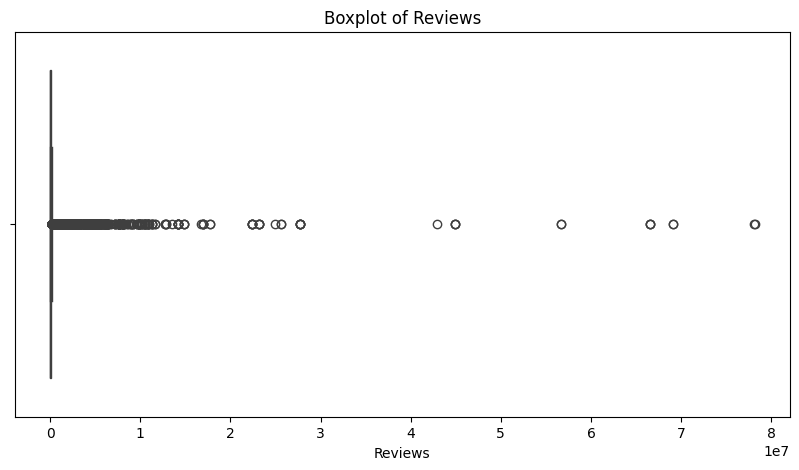

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(x=play_store['Reviews'])
plt.title('Boxplot of Reviews')
plt.show()

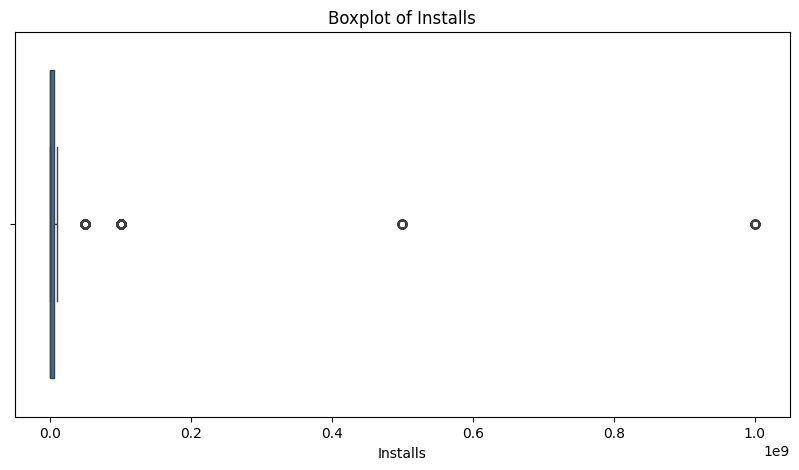

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=play_store['Installs'])
plt.title('Boxplot of Installs')
plt.show()

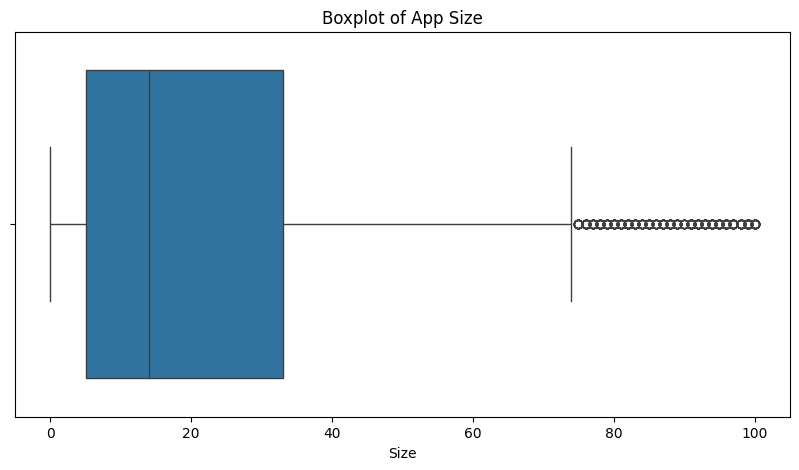

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=play_store['Size'])
plt.title('Boxplot of App Size')
plt.show()

Outlier Treatment

In [ ]:
columns = ['Rating', 'Reviews', 'Installs', 'Size', 'Price']

for col in columns:
    Q1 = play_store[col].quantile(0.25)
    Q3 = play_store[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = play_store[
        (play_store[col] < lower_bound) |
        (play_store[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")

Rating: 495 outliers
Reviews: 1555 outliers
Installs: 751 outliers
Size: 388 outliers
Price: 613 outliers


In [ ]:
for col in ['Rating', 'Reviews', 'Installs', 'Size', 'Price']:
    print(f"\n{col}")
    print("Minimum:", play_store[col].min())
    print("Maximum:", play_store[col].max())
    print("Mean:", play_store[col].mean())
    print("Median:", play_store[col].median())


Rating
Minimum: 1.0
Maximum: 5.0
Mean: 4.187876743139901
Median: 4.3

Reviews
Minimum: 1.0
Maximum: 78158306.0
Mean: 472776.3671839856
Median: 4714.5

Installs
Minimum: 1.0
Maximum: 1000000000.0
Mean: 16489648.148672964
Median: 500000.0

Size
Minimum: 0.00830078125
Maximum: 100.0
Mean: 22.747273451706455
Median: 14.0

Price
Minimum: 0.0
Maximum: 400.0
Mean: 0.963154520917679
Median: 0.0


In [ ]:
for col in ['Rating', 'Reviews', 'Installs', 'Size', 'Price']:
    print(f"\nTop 10 values in {col}:")
    print(play_store[col].nlargest(10).to_list())


Top 10 values in Rating:
[5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0]

Top 10 values in Reviews:
[78158306.0, 78128208.0, 69119316.0, 69109672.0, 66577446.0, 66577313.0, 66509917.0, 56646578.0, 56642847.0, 44893888.0]

Top 10 values in Installs:
[1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0, 1000000000.0]

Top 10 values in Size:
[100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]

Top 10 values in Price:
[400.0, 399.99, 399.99, 399.99, 399.99, 399.99, 399.99, 399.99, 399.99, 399.99]


In [ ]:
print("Invalid Ratings:")
print(play_store[(play_store['Rating'] < 1) | (play_store['Rating'] > 5)])

print("\nNegative Reviews:")
print(play_store[play_store['Reviews'] < 0])

print("\nNegative Installs:")
print(play_store[play_store['Installs'] < 0])

print("\nNegative Size:")
print(play_store[play_store['Size'] < 0])

print("\nNegative Price:")
print(play_store[play_store['Price'] < 0])

Invalid Ratings:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver]
Index: []

Negative Reviews:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver]
Index: []

Negative Installs:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver]
Index: []

Negative Size:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver]
Index: []

Negative Price:
Empty DataFrame
Columns: [App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver, Android Ver]
Index: []


In [ ]:
import numpy as np

play_store['Reviews_log'] = np.log1p(play_store['Reviews'])
play_store['Installs_log'] = np.log1p(play_store['Installs'])

In [ ]:
play_store[['Reviews', 'Reviews_log', 'Installs', 'Installs_log']].head()

,Reviews,Reviews_log,Installs,Installs_log
0,159.0,5.075174,10000.0,9.210440
1,967.0,6.875232,500000.0,13.122365
2,87510.0,11.379520,5000000.0,15.424949
3,215644.0,12.281389,50000000.0,17.727534
4,967.0,6.875232,100000.0,11.512935


Start Univariate Analysis

Rating Distribution

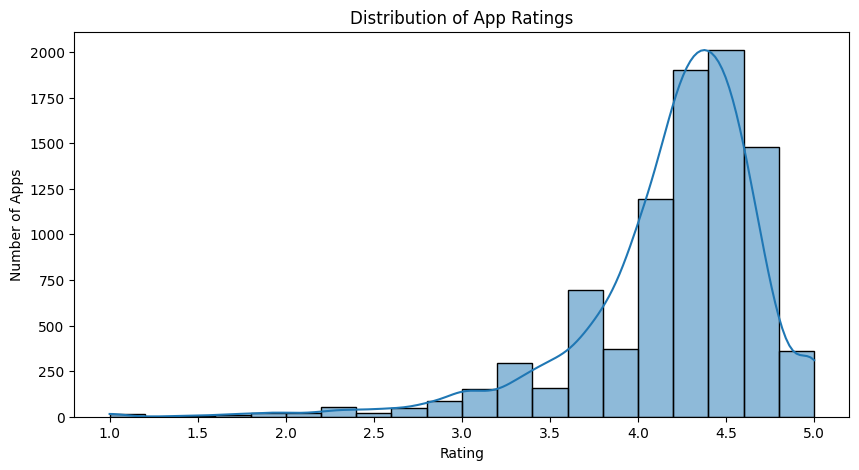

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=play_store,
    x='Rating',
    bins=20,
    kde=True
)

plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')

plt.show()

Number of Apps by Category

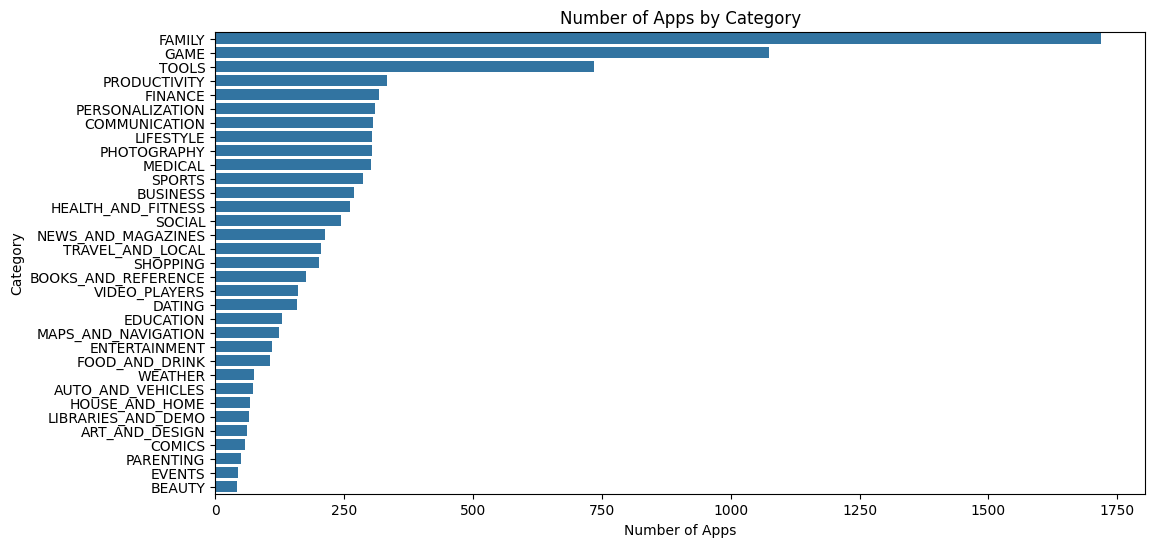

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=play_store,
    y='Category',
    order=play_store['Category'].value_counts().index
)

plt.title('Number of Apps by Category')
plt.xlabel('Number of Apps')
plt.ylabel('Category')

plt.show()

Reviews Distribution

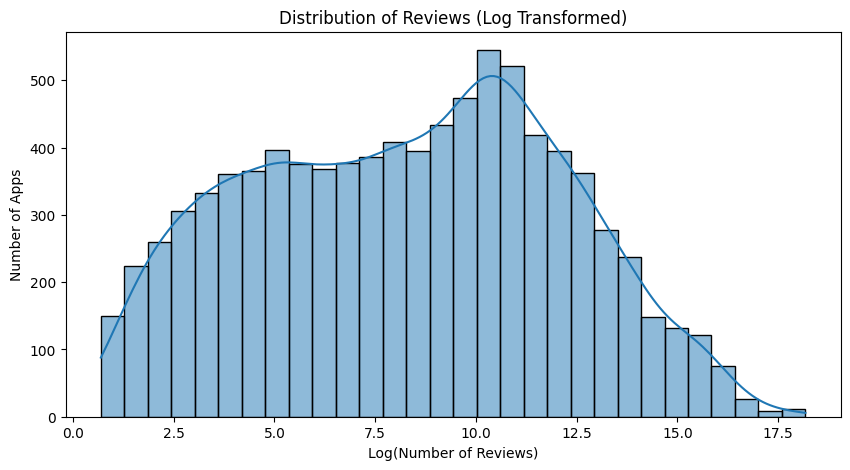

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=play_store,
    x='Reviews_log',
    bins=30,
    kde=True
)

plt.title('Distribution of Reviews (Log Transformed)')
plt.xlabel('Log(Number of Reviews)')
plt.ylabel('Number of Apps')

plt.show()

Installs Distribution

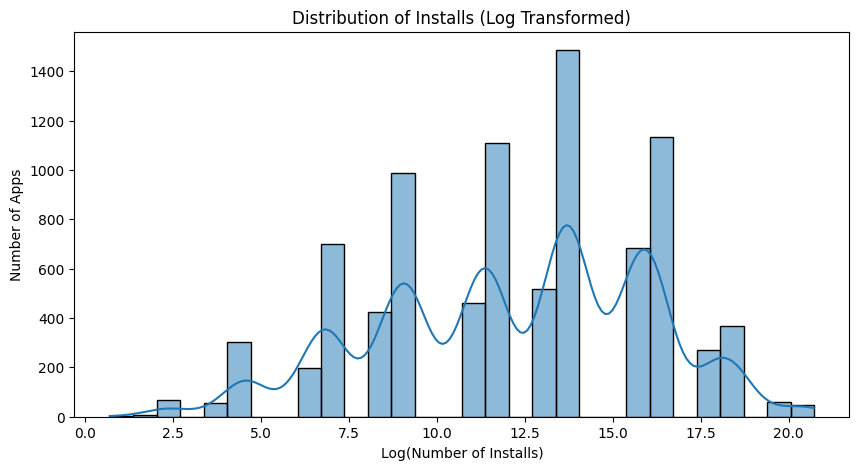

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=play_store,
    x='Installs_log',
    bins=30,
    kde=True
)

plt.title('Distribution of Installs (Log Transformed)')
plt.xlabel('Log(Number of Installs)')
plt.ylabel('Number of Apps')

plt.show()

Free vs Paid Apps

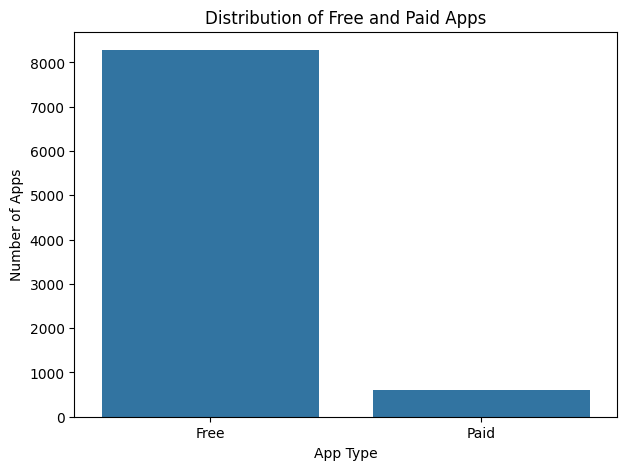

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=play_store,
    x='Type'
)

plt.title('Distribution of Free and Paid Apps')
plt.xlabel('App Type')
plt.ylabel('Number of Apps')

plt.show()

Bivariate analysis

1. Category vs Rating — Average Rating

In [ ]:
category_rating = play_store.groupby('Category')['Rating'].mean().sort_values(ascending=False)

category_rating

,Rating
Category,
EVENTS,4.435556
EDUCATION,4.375969
ART_AND_DESIGN,4.358065
BOOKS_AND_REFERENCE,4.347458
PERSONALIZATION,4.333871
PARENTING,4.300000
GAME,4.281285
BEAUTY,4.278571
HEALTH_AND_FITNESS,4.261450


create the visualization:

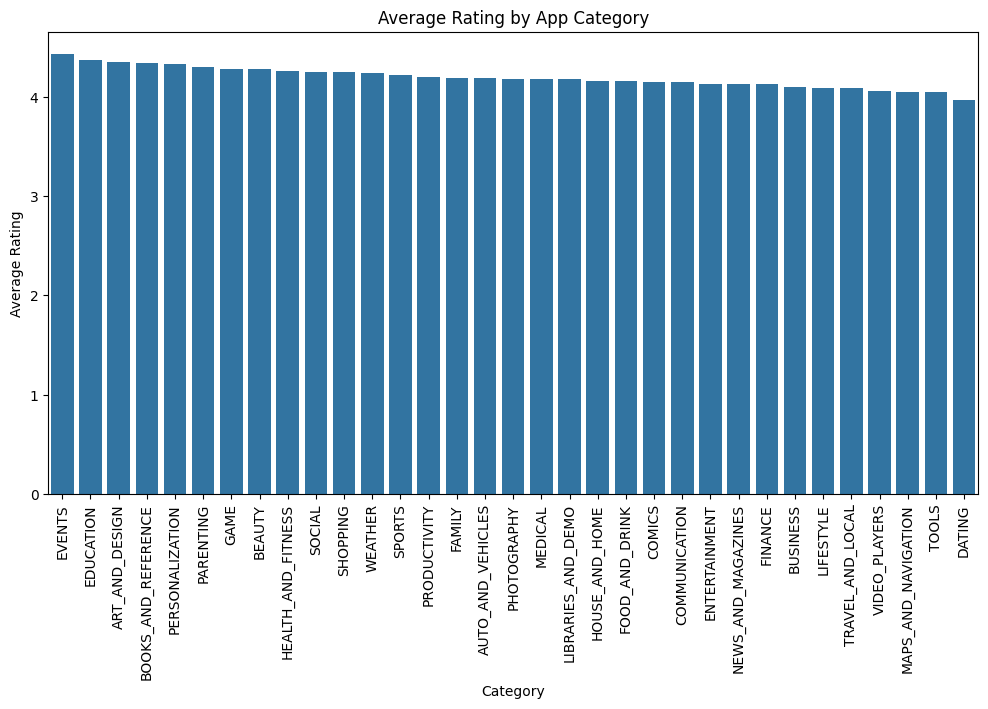

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_rating.index,
    y=category_rating.values
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Rating')
plt.title('Average Rating by App Category')

plt.show()

2. Category vs Reviews

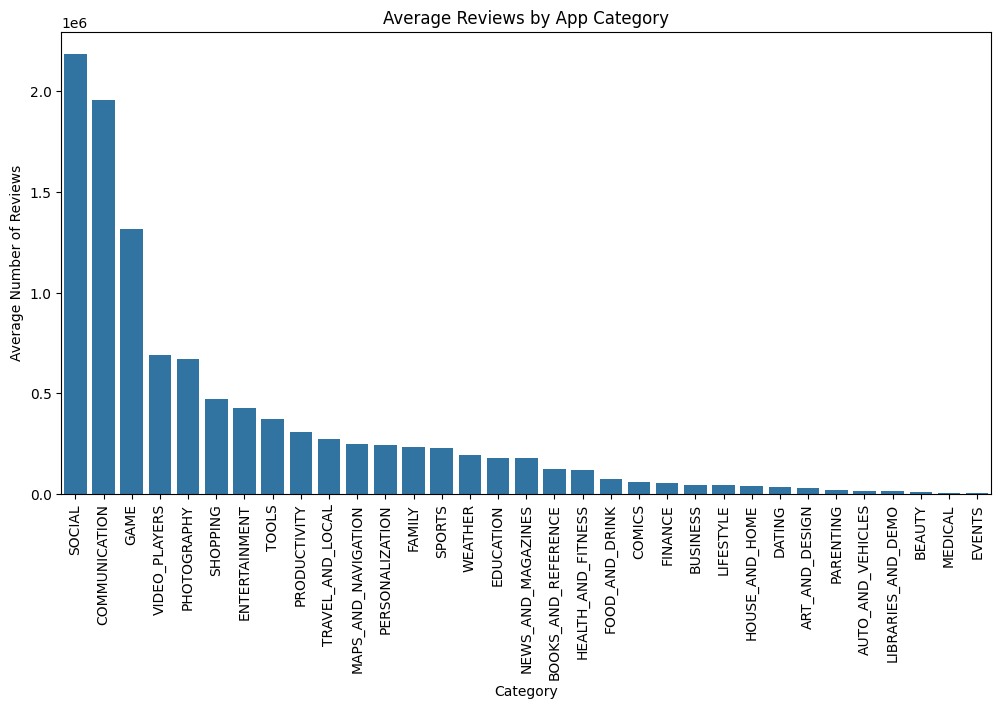

In [ ]:
category_reviews = play_store.groupby('Category')['Reviews'].mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_reviews.index,
    y=category_reviews.values
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Number of Reviews')
plt.title('Average Reviews by App Category')

plt.show()

3. Category vs Installs

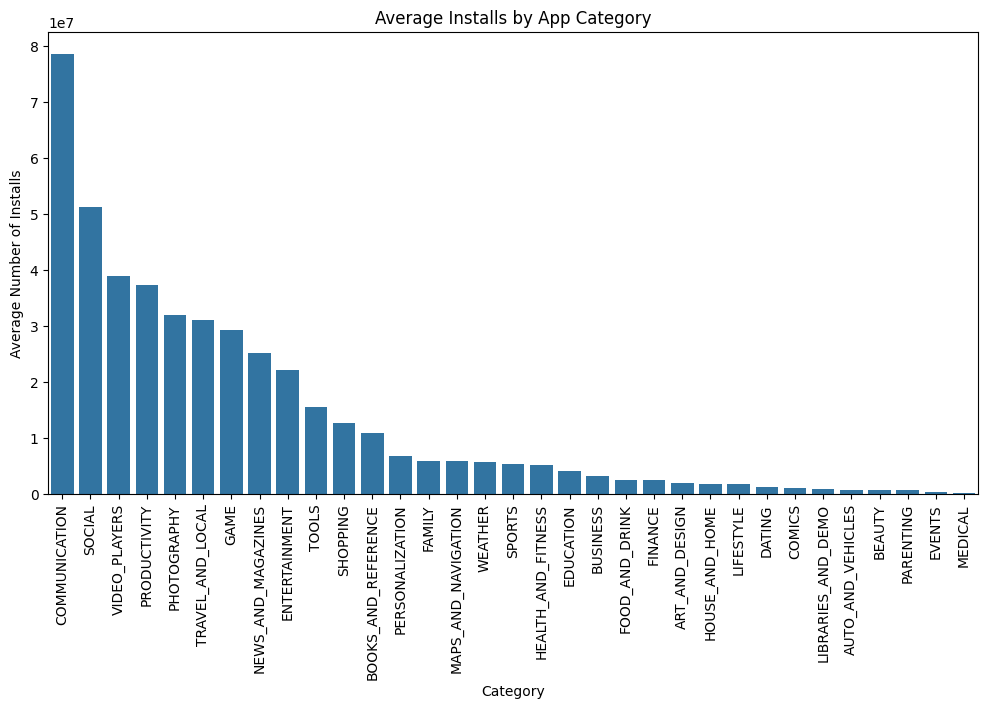

In [ ]:
category_installs = play_store.groupby('Category')['Installs'].mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_installs.index,
    y=category_installs.values
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Number of Installs')
plt.title('Average Installs by App Category')

plt.show()

4. Rating vs Reviews

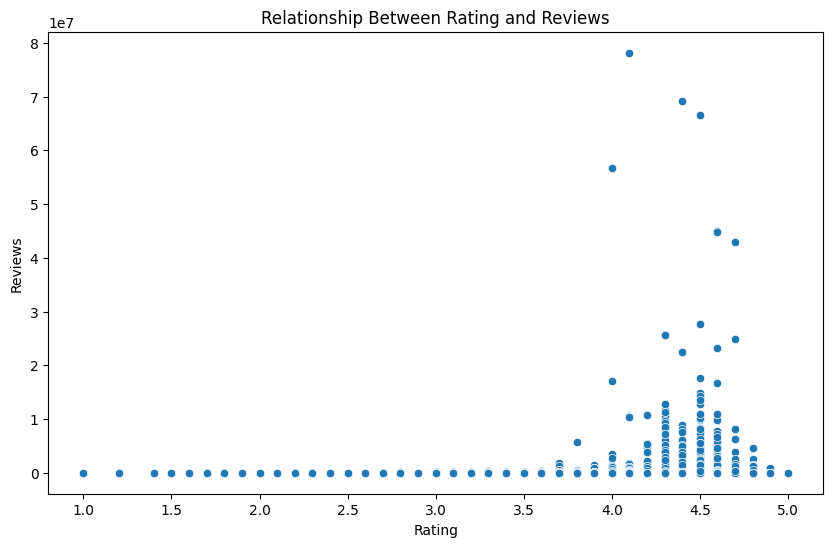

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=play_store,
    x='Rating',
    y='Reviews'
)

plt.xlabel('Rating')
plt.ylabel('Reviews')
plt.title('Relationship Between Rating and Reviews')

plt.show()

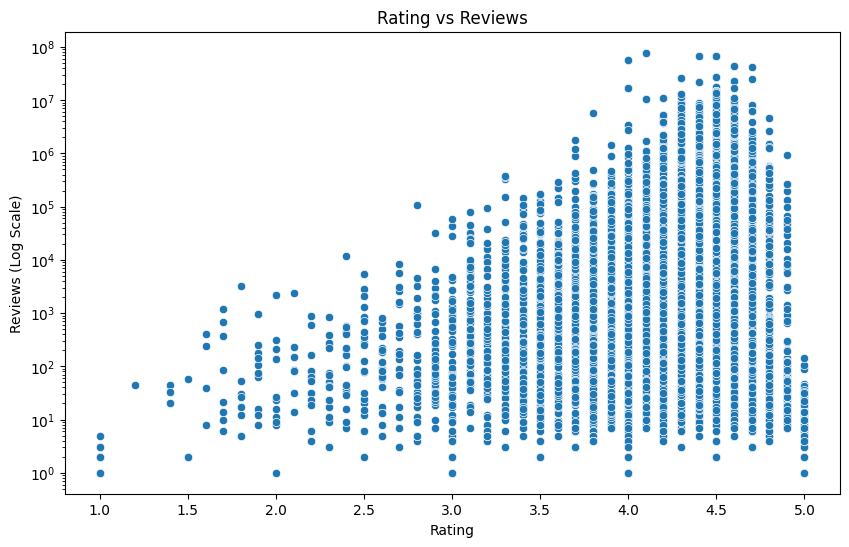

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=play_store,
    x='Rating',
    y='Reviews'
)

plt.yscale('log')

plt.xlabel('Rating')
plt.ylabel('Reviews (Log Scale)')
plt.title('Rating vs Reviews')

plt.show()

5. Rating vs Installs

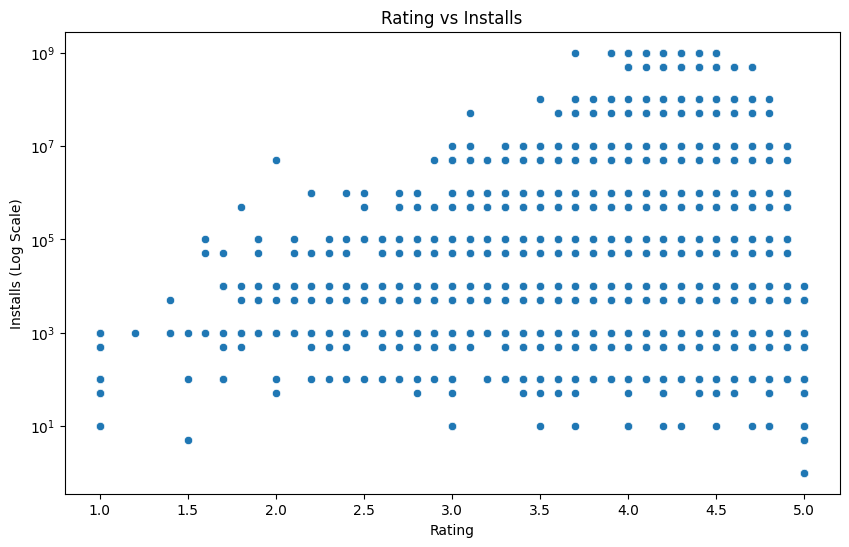

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=play_store,
    x='Rating',
    y='Installs'
)

plt.yscale('log')

plt.xlabel('Rating')
plt.ylabel('Installs (Log Scale)')
plt.title('Rating vs Installs')

plt.show()

6. Type vs Rating

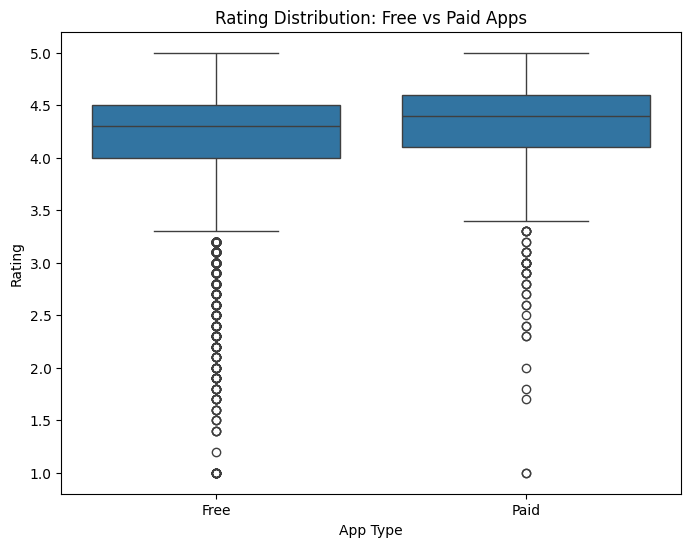

In [ ]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=play_store,
    x='Type',
    y='Rating'
)

plt.xlabel('App Type')
plt.ylabel('Rating')
plt.title('Rating Distribution: Free vs Paid Apps')

plt.show()

7. Content Rating vs Rating

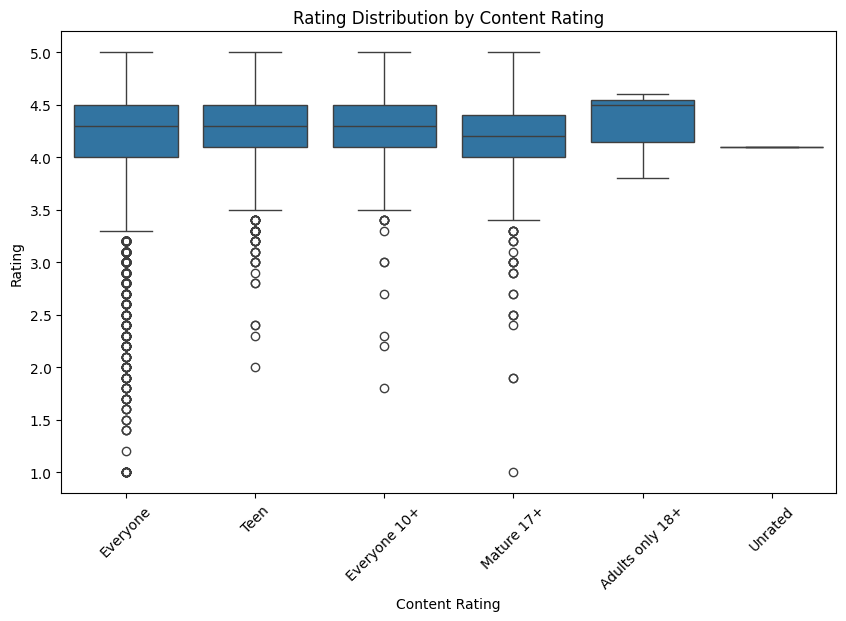

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=play_store,
    x='Content Rating',
    y='Rating'
)

plt.xticks(rotation=45)
plt.xlabel('Content Rating')
plt.ylabel('Rating')
plt.title('Rating Distribution by Content Rating')

plt.show()

8. Price vs Rating

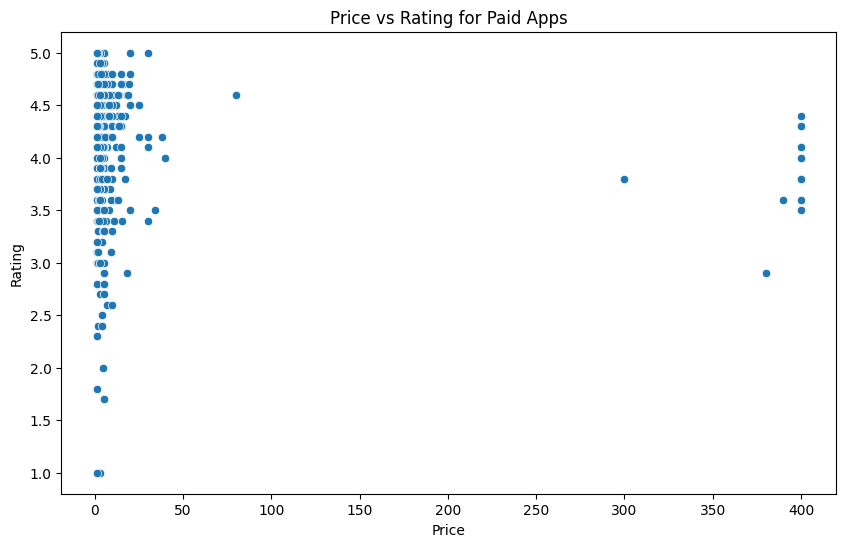

In [ ]:
paid_apps = play_store[play_store['Type'] == 'Paid']

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=paid_apps,
    x='Price',
    y='Rating'
)

plt.xlabel('Price')
plt.ylabel('Rating')
plt.title('Price vs Rating for Paid Apps')

plt.show()

9. Size vs Rating

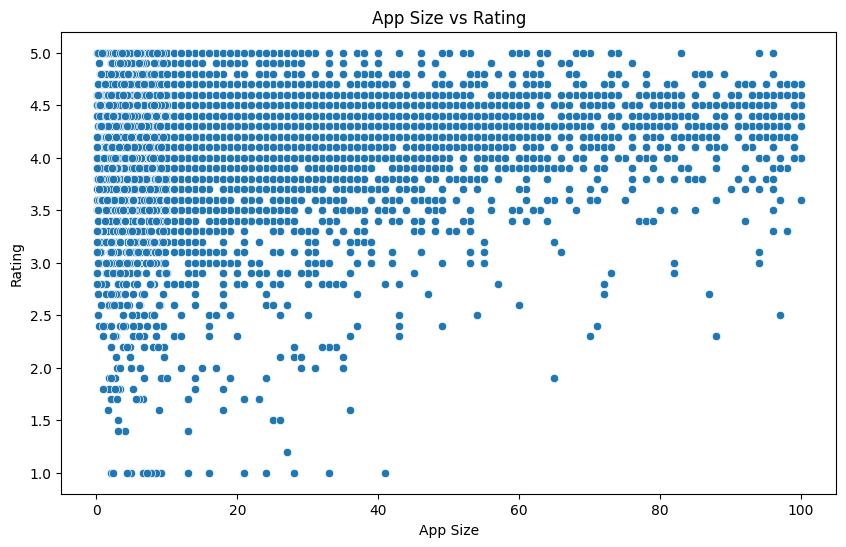

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=play_store,
    x='Size',
    y='Rating'
)

plt.xlabel('App Size')
plt.ylabel('Rating')
plt.title('App Size vs Rating')

plt.show()

Multivariate Analysis

1. Correlation Analysis

In [ ]:
numerical_cols = [
    'Rating',
    'Reviews',
    'Installs',
    'Price',
    'Size'
]

correlation = play_store[numerical_cols].corr()

correlation

,Rating,Reviews,Installs,Price,Size
Rating,1.000000,0.068732,0.050886,-0.022355,0.081969
Reviews,0.068732,1.000000,0.633429,-0.009558,0.240103
Installs,0.050886,0.633429,1.000000,-0.011329,0.167032
Price,-0.022355,-0.009558,-0.011329,1.000000,-0.026822
Size,0.081969,0.240103,0.167032,-0.026822,1.000000


2. Correlation Heatmap

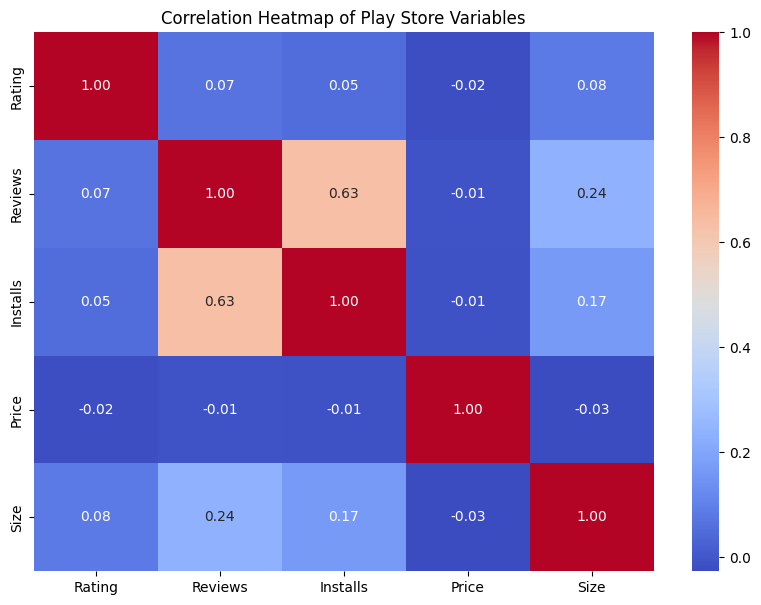

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Play Store Variables')
plt.show()

3. Category + Rating + Reviews

In [ ]:
category_analysis = (
    play_store
    .groupby('Category')
    .agg(
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .sort_values('Avg_Installs', ascending=False)
)

category_analysis

,Avg_Rating,Avg_Reviews,Avg_Installs
Category,,,
COMMUNICATION,4.151466,1.958544e+06,7.867180e+07
SOCIAL,4.254918,2.186789e+06,5.128624e+07
VIDEO_PLAYERS,4.063750,6.898731e+05,3.888686e+07
PRODUCTIVITY,4.201796,3.070486e+05,3.731458e+07
PHOTOGRAPHY,4.182895,6.720308e+05,3.197777e+07
TRAVEL_AND_LOCAL,4.094146,2.710488e+05,3.103346e+07
GAME,4.281285,1.318002e+06,2.937045e+07
NEWS_AND_MAGAZINES,4.128505,1.787145e+05,2.520145e+07
ENTERTAINMENT,4.136036,4.285650e+05,2.212306e+07


4. Category vs Rating and Installs

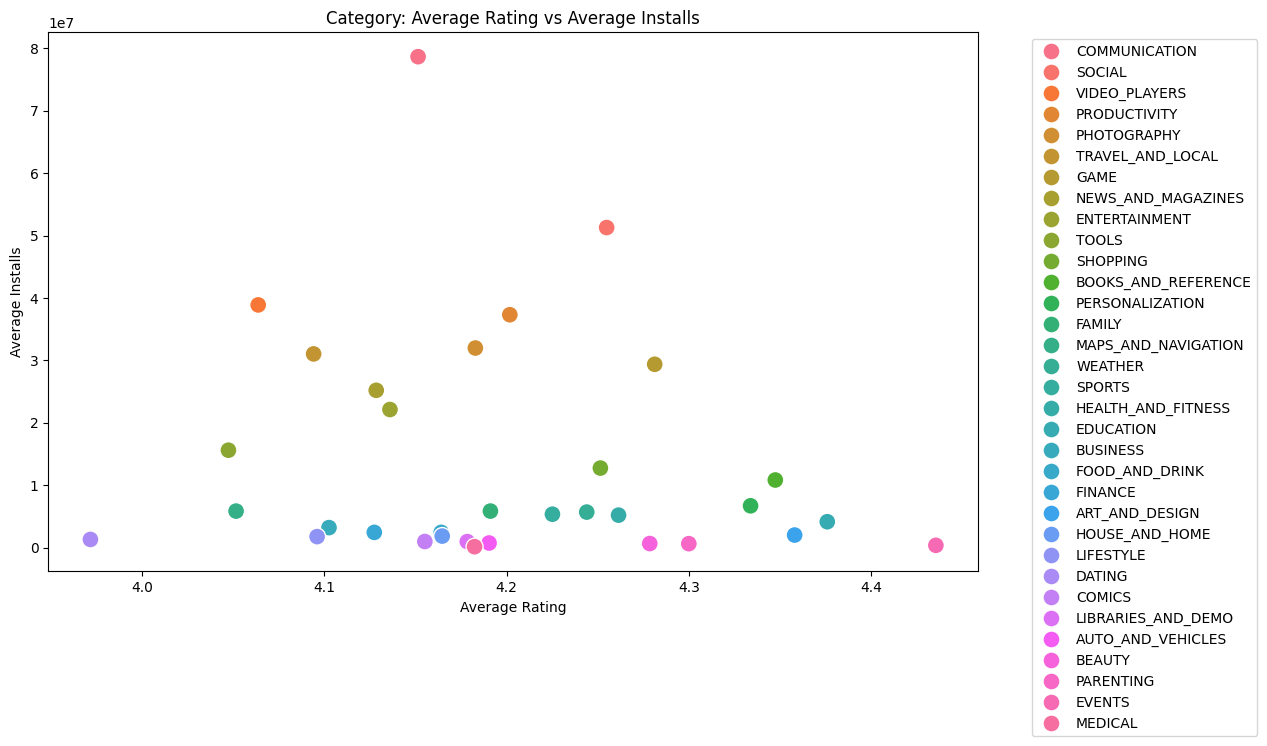

In [ ]:
plt.figure(figsize=(12,7))

sns.scatterplot(
    data=category_analysis,
    x='Avg_Rating',
    y='Avg_Installs',
    hue=category_analysis.index,
    s=150
)

plt.xlabel('Average Rating')
plt.ylabel('Average Installs')
plt.title('Category: Average Rating vs Average Installs')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

5. Category vs Reviews and Installs

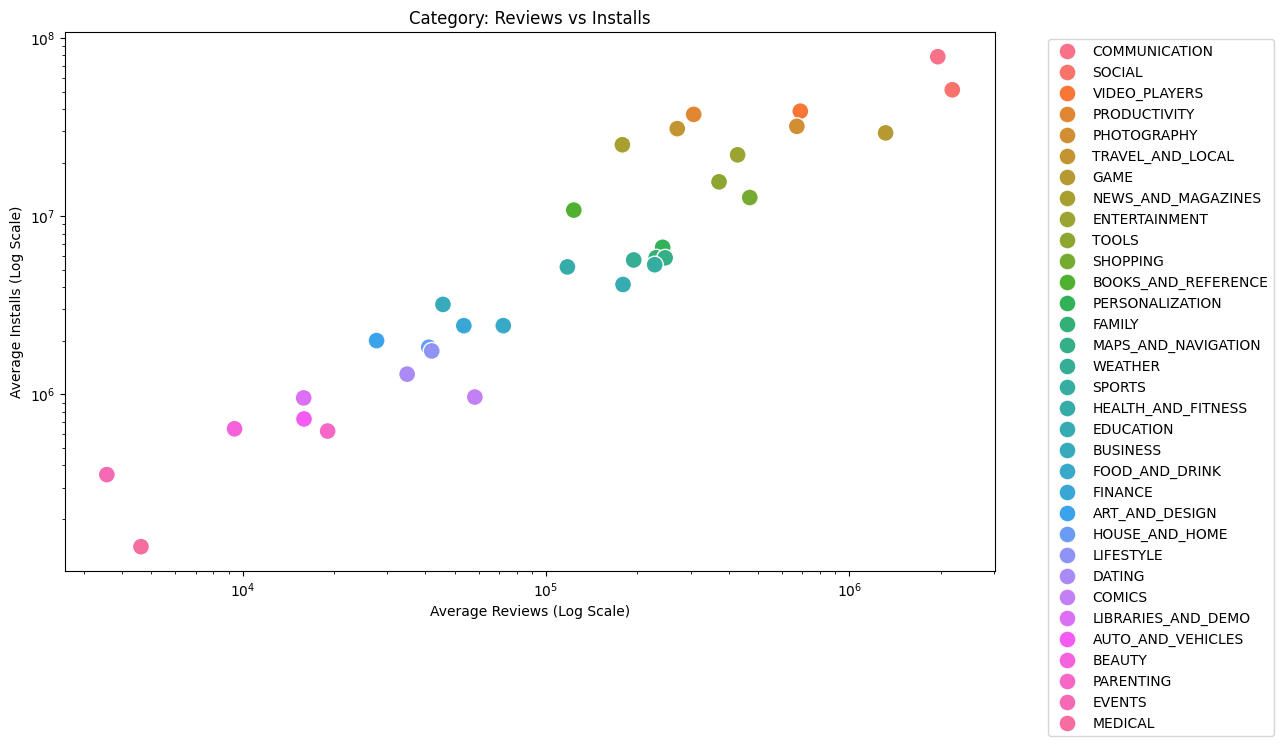

In [ ]:
plt.figure(figsize=(12,7))

sns.scatterplot(
    data=category_analysis,
    x='Avg_Reviews',
    y='Avg_Installs',
    hue=category_analysis.index,
    s=150
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Average Reviews (Log Scale)')
plt.ylabel('Average Installs (Log Scale)')
plt.title('Category: Reviews vs Installs')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

6. Top Categories by Installs + Rating

In [ ]:
top_categories = (
    category_analysis
    .sort_values('Avg_Installs', ascending=False)
    .head(10)
)

top_categories

,Avg_Rating,Avg_Reviews,Avg_Installs
Category,,,
COMMUNICATION,4.151466,1.958544e+06,7.867180e+07
SOCIAL,4.254918,2.186789e+06,5.128624e+07
VIDEO_PLAYERS,4.063750,6.898731e+05,3.888686e+07
PRODUCTIVITY,4.201796,3.070486e+05,3.731458e+07
PHOTOGRAPHY,4.182895,6.720308e+05,3.197777e+07
TRAVEL_AND_LOCAL,4.094146,2.710488e+05,3.103346e+07
GAME,4.281285,1.318002e+06,2.937045e+07
NEWS_AND_MAGAZINES,4.128505,1.787145e+05,2.520145e+07
ENTERTAINMENT,4.136036,4.285650e+05,2.212306e+07


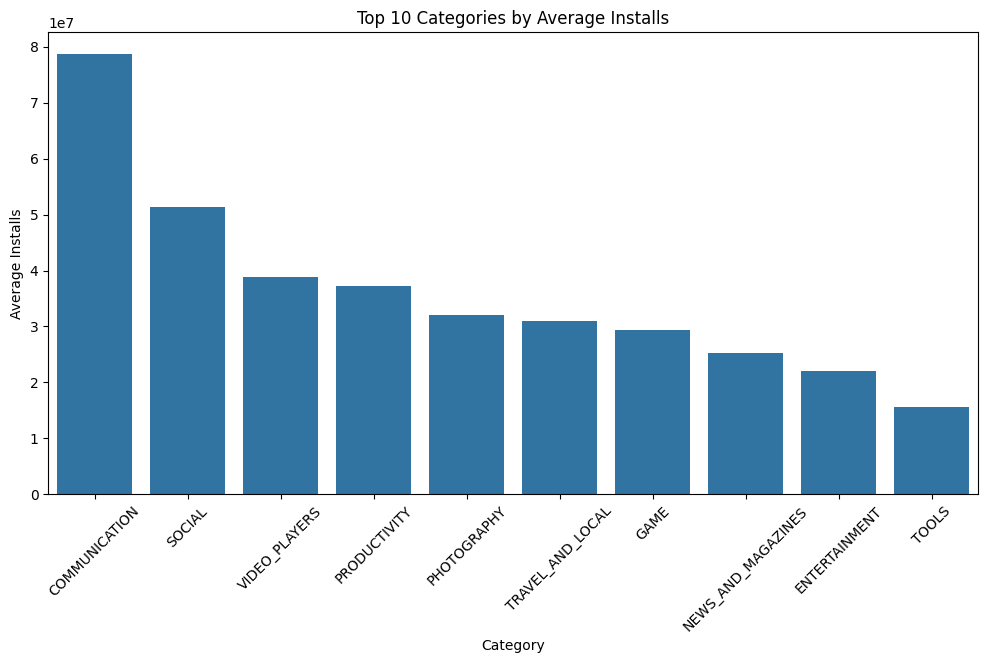

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_categories.reset_index(),
    x='Category',
    y='Avg_Installs'
)

plt.xticks(rotation=45)
plt.xlabel('Category')
plt.ylabel('Average Installs')
plt.title('Top 10 Categories by Average Installs')

plt.show()

7. Free/Paid + Rating + Reviews

In [ ]:
type_analysis = (
    play_store
    .groupby('Type')
    .agg(
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean'),
        App_Count=('Type', 'count')
    )
)

type_analysis

,Avg_Rating,Avg_Reviews,Avg_Installs,App_Count
Type,,,,
Free,4.182425,506682.471675,1.770223e+07,8279
Paid,4.261501,14850.365416,1.129078e+05,613


8. Type + Rating + Installs

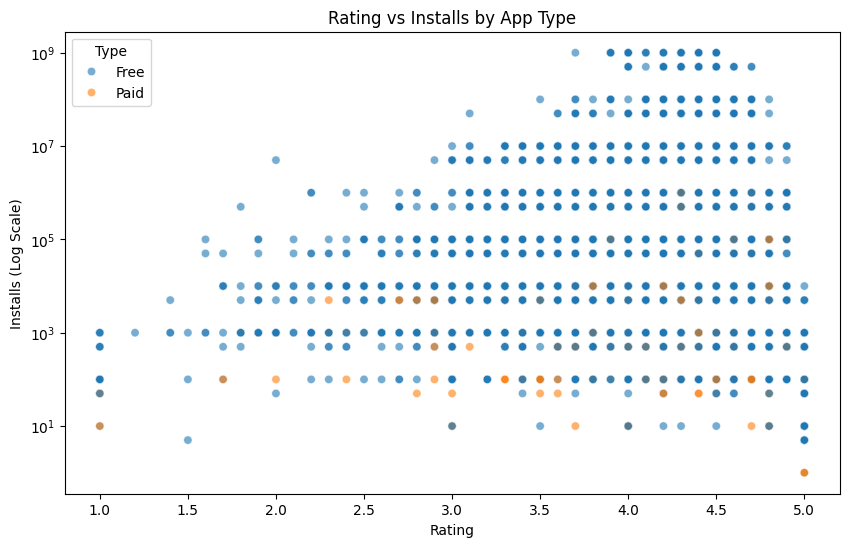

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=play_store,
    x='Rating',
    y='Installs',
    hue='Type',
    alpha=0.6
)

plt.yscale('log')

plt.xlabel('Rating')
plt.ylabel('Installs (Log Scale)')
plt.title('Rating vs Installs by App Type')

plt.show()

9. Category + Type + Rating

In [ ]:
category_type_rating = (
    play_store
    .groupby(['Category', 'Type'])['Rating']
    .mean()
    .reset_index()
)

category_type_rating

,Category,Type,Rating
0,ART_AND_DESIGN,Free,4.338983
1,ART_AND_DESIGN,Paid,4.733333
2,AUTO_AND_VEHICLES,Free,4.184722
3,AUTO_AND_VEHICLES,Paid,4.600000
4,BEAUTY,Free,4.278571
...,...,...,...
56,TRAVEL_AND_LOCAL,Paid,4.100000
57,VIDEO_PLAYERS,Free,4.062821
58,VIDEO_PLAYERS,Paid,4.100000
59,WEATHER,Free,4.230882


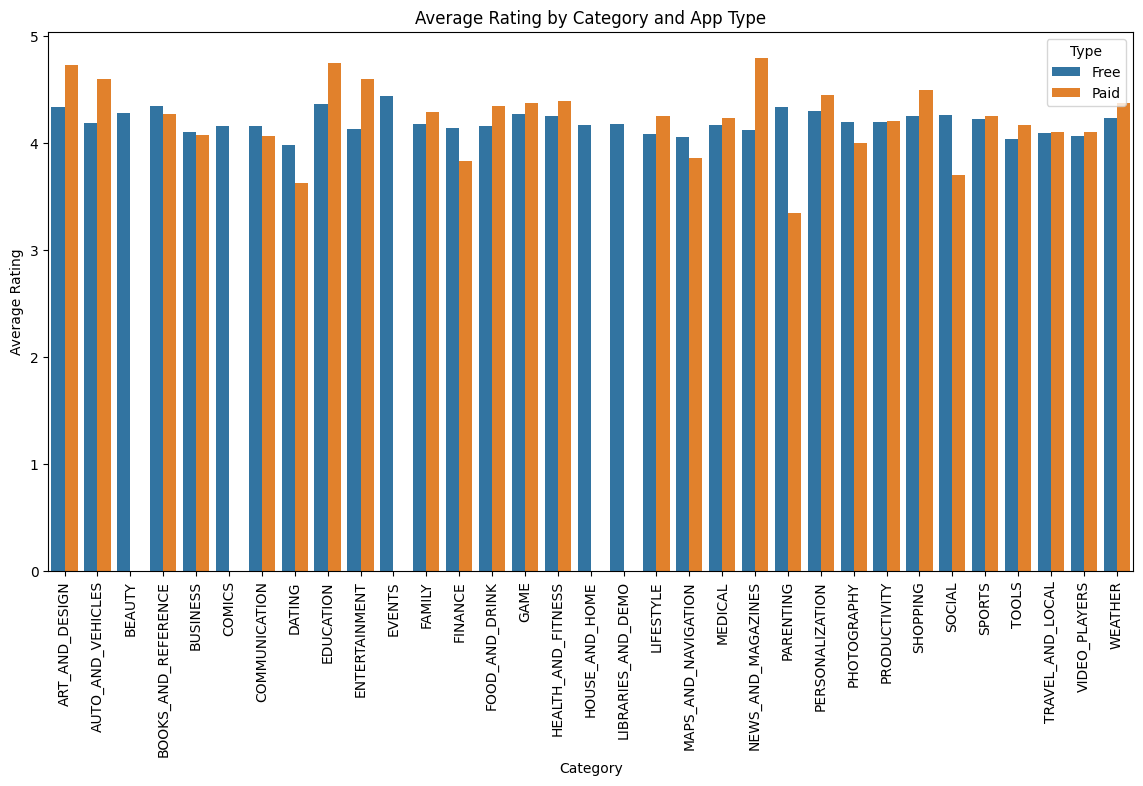

In [ ]:
plt.figure(figsize=(14,7))

sns.barplot(
    data=category_type_rating,
    x='Category',
    y='Rating',
    hue='Type'
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Rating')
plt.title('Average Rating by Category and App Type')

plt.show()

10. Category + Installs + Reviews

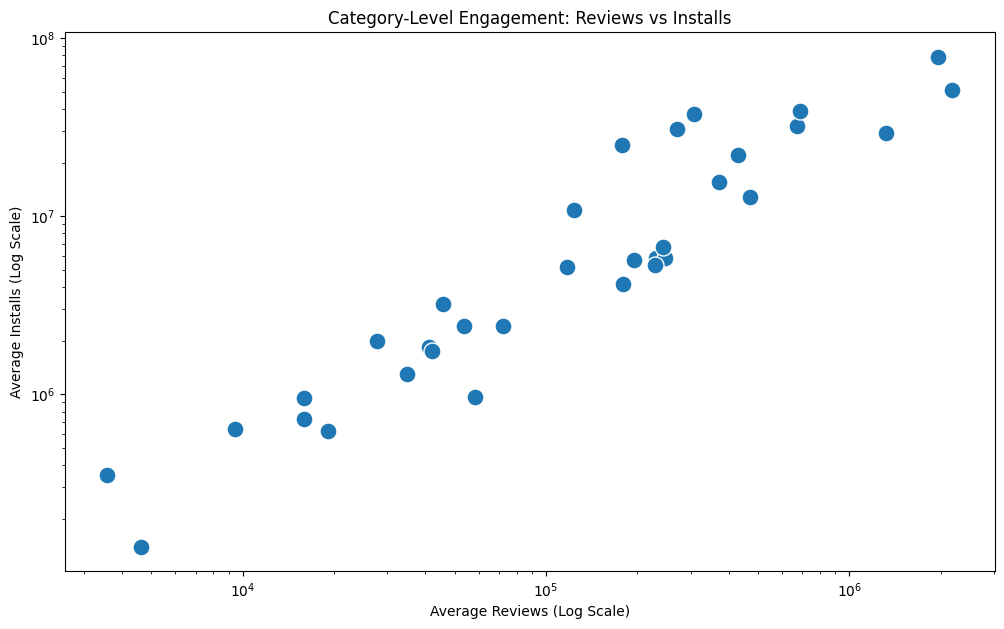

In [ ]:
category_engagement = (
    play_store
    .groupby('Category')
    .agg(
        Avg_Installs=('Installs', 'mean'),
        Avg_Reviews=('Reviews', 'mean')
    )
    .reset_index()
)

plt.figure(figsize=(12,7))

sns.scatterplot(
    data=category_engagement,
    x='Avg_Reviews',
    y='Avg_Installs',
    s=150
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Average Reviews (Log Scale)')
plt.ylabel('Average Installs (Log Scale)')
plt.title('Category-Level Engagement: Reviews vs Installs')

plt.show()

Create a Business Summary *Table*

In [ ]:
business_summary = (
    play_store
    .groupby('Category')
    .agg(
        App_Count=('Category', 'count'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .reset_index()
)

business_summary['Avg_Rating'] = business_summary['Avg_Rating'].round(2)
business_summary

,Category,App_Count,Avg_Rating,Avg_Reviews,Avg_Installs
0,ART_AND_DESIGN,62,4.36,2.765116e+04,2.003760e+06
1,AUTO_AND_VEHICLES,73,4.19,1.594014e+04,7.278055e+05
2,BEAUTY,42,4.28,9.407929e+03,6.408619e+05
3,BOOKS_AND_REFERENCE,177,4.35,1.235752e+05,1.082651e+07
4,BUSINESS,270,4.10,4.576928e+04,3.198215e+06
5,COMICS,58,4.16,5.830940e+04,9.661397e+05
6,COMMUNICATION,307,4.15,1.958544e+06,7.867180e+07
7,DATING,159,3.97,3.487525e+04,1.298883e+06
8,EDUCATION,129,4.38,1.795715e+05,4.138388e+06
9,ENTERTAINMENT,111,4.14,4.285650e+05,2.212306e+07


This gives us one table containing the major success indicators:

Identify High-Engagement Categories

In [ ]:
business_summary['Install_Rank'] = (
    business_summary['Avg_Installs']
    .rank(method='dense', ascending=False)
)

top_install_categories = (
    business_summary
    .sort_values('Avg_Installs', ascending=False)
    .head(10)
)

top_install_categories

,Category,App_Count,Avg_Rating,Avg_Reviews,Avg_Installs,Install_Rank
6,COMMUNICATION,307,4.15,1.958544e+06,7.867180e+07,1.0
27,SOCIAL,244,4.25,2.186789e+06,5.128624e+07,2.0
31,VIDEO_PLAYERS,160,4.06,6.898731e+05,3.888686e+07,3.0
25,PRODUCTIVITY,334,4.20,3.070486e+05,3.731458e+07,4.0
24,PHOTOGRAPHY,304,4.18,6.720308e+05,3.197777e+07,5.0
30,TRAVEL_AND_LOCAL,205,4.09,2.710488e+05,3.103346e+07,6.0
14,GAME,1074,4.28,1.318002e+06,2.937045e+07,7.0
21,NEWS_AND_MAGAZINES,214,4.13,1.787145e+05,2.520145e+07,8.0
9,ENTERTAINMENT,111,4.14,4.285650e+05,2.212306e+07,9.0
29,TOOLS,734,4.05,3.721855e+05,1.560044e+07,10.0


These categories represent areas with comparatively high user adoption.

For an app developer, these categories can indicate strong existing demand, although competition should also be considered.

Identify Highly Rated Categories

In [ ]:
top_rated_categories = (
    business_summary
    .sort_values('Avg_Rating', ascending=False)
    .head(10)
)

top_rated_categories

,Category,App_Count,Avg_Rating,Avg_Reviews,Avg_Installs,Install_Rank
10,EVENTS,45,4.44,3.568667e+03,3.544313e+05,32.0
8,EDUCATION,129,4.38,1.795715e+05,4.138388e+06,19.0
0,ART_AND_DESIGN,62,4.36,2.765116e+04,2.003760e+06,23.0
3,BOOKS_AND_REFERENCE,177,4.35,1.235752e+05,1.082651e+07,12.0
23,PERSONALIZATION,310,4.33,2.425575e+05,6.691461e+06,13.0
22,PARENTING,50,4.30,1.907218e+04,6.223222e+05,31.0
2,BEAUTY,42,4.28,9.407929e+03,6.408619e+05,30.0
14,GAME,1074,4.28,1.318002e+06,2.937045e+07,7.0
15,HEALTH_AND_FITNESS,262,4.26,1.177293e+05,5.194680e+06,18.0
26,SHOPPING,202,4.25,4.699553e+05,1.273927e+07,11.0


But there's an important analytical issue here.

A category could have a very high average rating simply because it contains relatively few apps.

So we should not say:

"Highest-rated category = best category."

Find Categories With High Rating AND High Installs

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

business_summary[['Rating_Score', 'Install_Score']] = scaler.fit_transform(
    business_summary[['Avg_Rating', 'Avg_Installs']]
)

business_summary['Success_Score'] = (
    business_summary['Rating_Score'] * 0.4 +
    business_summary['Install_Score'] * 0.6
)

business_summary.sort_values(
    'Success_Score',
    ascending=False
).head(10)

,Category,App_Count,Avg_Rating,Avg_Reviews,Avg_Installs,Install_Rank,Rating_Score,Install_Score,Success_Score
6,COMMUNICATION,307,4.15,1.958544e+06,7.867180e+07,1.0,0.382979,1.000000,0.753191
27,SOCIAL,244,4.25,2.186789e+06,5.128624e+07,2.0,0.595745,0.651282,0.629067
14,GAME,1074,4.28,1.318002e+06,2.937045e+07,7.0,0.659574,0.372215,0.487159
25,PRODUCTIVITY,334,4.20,3.070486e+05,3.731458e+07,4.0,0.489362,0.473372,0.479768
24,PHOTOGRAPHY,304,4.18,6.720308e+05,3.197777e+07,5.0,0.446809,0.405415,0.421973
3,BOOKS_AND_REFERENCE,177,4.35,1.235752e+05,1.082651e+07,12.0,0.808511,0.136083,0.405054
10,EVENTS,45,4.44,3.568667e+03,3.544313e+05,32.0,1.000000,0.002735,0.401641
8,EDUCATION,129,4.38,1.795715e+05,4.138388e+06,19.0,0.872340,0.050919,0.379488
31,VIDEO_PLAYERS,160,4.06,6.898731e+05,3.888686e+07,3.0,0.191489,0.493393,0.372632
23,PERSONALIZATION,310,4.33,2.425575e+05,6.691461e+06,13.0,0.765957,0.083429,0.356440


Why give installs more weight?

Because the project is specifically interested in engagement and success.

Rating represents user satisfaction.

Installs represent market reach/adoption.

So:

Success ≠ Rating alone

Investigate Reviews vs Installs

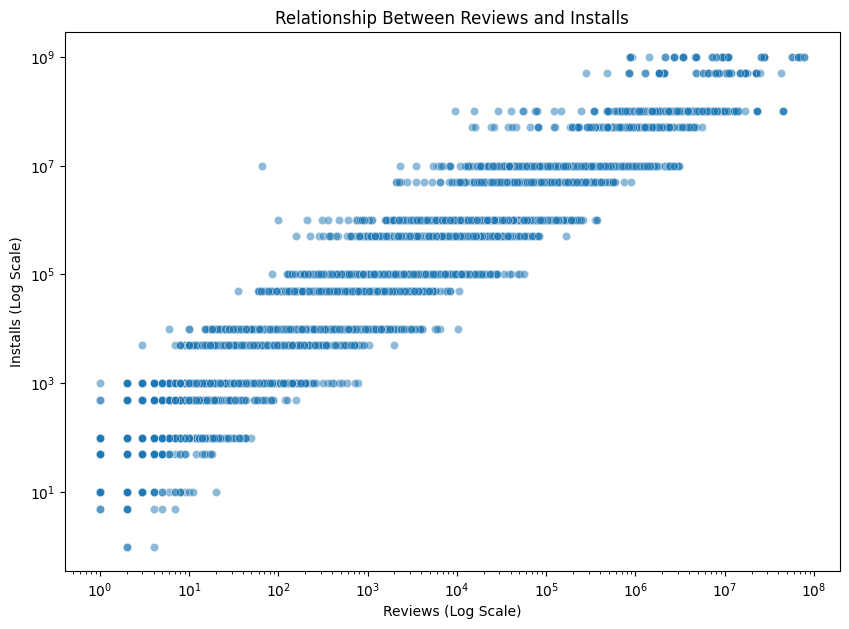

In [ ]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=play_store,
    x='Reviews',
    y='Installs',
    alpha=0.5
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Reviews (Log Scale)')
plt.ylabel('Installs (Log Scale)')
plt.title('Relationship Between Reviews and Installs')

plt.show()

Are apps with more installations also receiving more user engagement?

We expect some relationship because more users provide more opportunities for reviews, but the visualization tells us how strong and consistent that relationship is.

Calculate the Correlation

In [ ]:
play_store[['Reviews', 'Installs']].corr()

,Reviews,Installs
Reviews,1.000000,0.633429
Installs,0.633429,1.000000


In [ ]:
play_store[
    ['Rating', 'Reviews', 'Installs', 'Price', 'Size']
].corr()

,Rating,Reviews,Installs,Price,Size
Rating,1.000000,0.068732,0.050886,-0.022355,0.081969
Reviews,0.068732,1.000000,0.633429,-0.009558,0.240103
Installs,0.050886,0.633429,1.000000,-0.011329,0.167032
Price,-0.022355,-0.009558,-0.011329,1.000000,-0.026822
Size,0.081969,0.240103,0.167032,-0.026822,1.000000


Correlation indicates the strength and direction of a linear association; it does not establish causation

Analyze Free vs Paid Apps

In [ ]:
type_summary = (
    play_store
    .groupby('Type')
    .agg(
        App_Count=('Type', 'count'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .reset_index()
)

type_summary.round(2)

,Type,App_Count,Avg_Rating,Avg_Reviews,Avg_Installs
0,Free,8279,4.18,506682.47,17702227.18
1,Paid,613,4.26,14850.37,112907.80


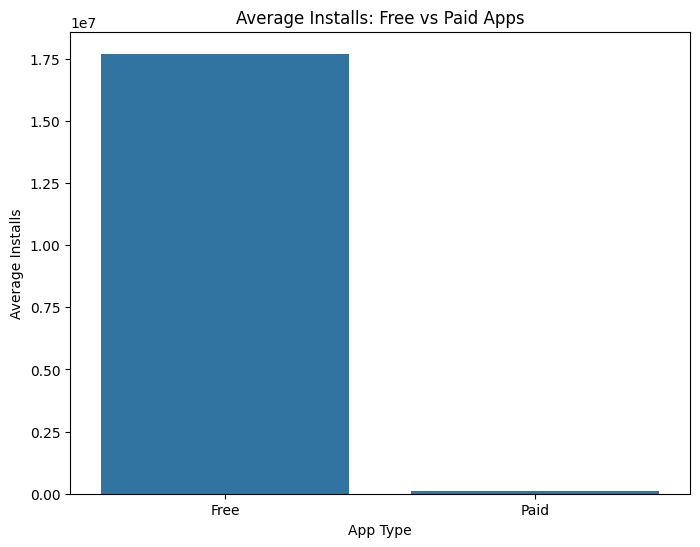

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=type_summary,
    x='Type',
    y='Avg_Installs'
)

plt.xlabel('App Type')
plt.ylabel('Average Installs')
plt.title('Average Installs: Free vs Paid Apps')

plt.show()

Does monetization type appear to be associated with app adoption?

This is useful for developers deciding whether their app should use a free or paid model.

Identify the Most Engaging Categories

In [ ]:
engagement_summary = (
    play_store
    .groupby('Category')
    .agg(
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .reset_index()
)

engagement_summary

,Category,Avg_Reviews,Avg_Installs
0,ART_AND_DESIGN,2.765116e+04,2.003760e+06
1,AUTO_AND_VEHICLES,1.594014e+04,7.278055e+05
2,BEAUTY,9.407929e+03,6.408619e+05
3,BOOKS_AND_REFERENCE,1.235752e+05,1.082651e+07
4,BUSINESS,4.576928e+04,3.198215e+06
5,COMICS,5.830940e+04,9.661397e+05
6,COMMUNICATION,1.958544e+06,7.867180e+07
7,DATING,3.487525e+04,1.298883e+06
8,EDUCATION,1.795715e+05,4.138388e+06
9,ENTERTAINMENT,4.285650e+05,2.212306e+07


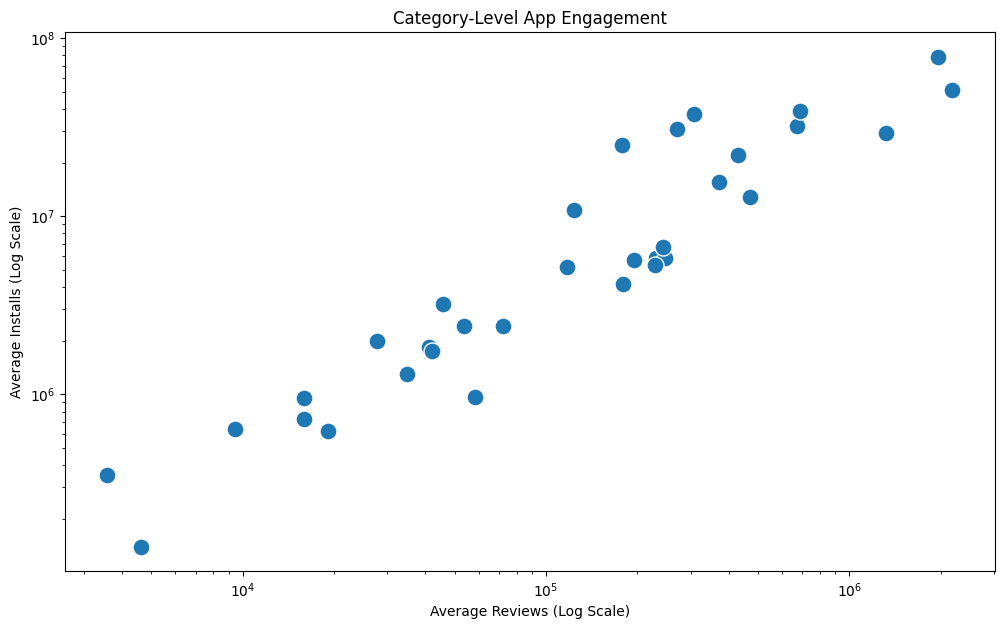

In [ ]:
plt.figure(figsize=(12,7))

sns.scatterplot(
    data=engagement_summary,
    x='Avg_Reviews',
    y='Avg_Installs',
    s=150
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Average Reviews (Log Scale)')
plt.ylabel('Average Installs (Log Scale)')
plt.title('Category-Level App Engagement')

plt.show()

Create Final Insight Table

In [ ]:
final_category_analysis = (
    play_store
    .groupby('Category')
    .agg(
        Apps=('Category', 'count'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .reset_index()
)

final_category_analysis = final_category_analysis.round(2)

final_category_analysis.sort_values(
    'Avg_Installs',
    ascending=False
).head(10)

,Category,Apps,Avg_Rating,Avg_Reviews,Avg_Installs
6,COMMUNICATION,307,4.15,1958544.27,78671796.51
27,SOCIAL,244,4.25,2186788.93,51286235.55
31,VIDEO_PLAYERS,160,4.06,689873.08,38886857.50
25,PRODUCTIVITY,334,4.20,307048.62,37314581.38
24,PHOTOGRAPHY,304,4.18,672030.81,31977773.45
30,TRAVEL_AND_LOCAL,205,4.09,271048.84,31033460.00
14,GAME,1074,4.28,1318001.75,29370449.46
21,NEWS_AND_MAGAZINES,214,4.13,178714.53,25201451.64
9,ENTERTAINMENT,111,4.14,428565.01,22123063.06
29,TOOLS,734,4.05,372185.51,15600442.10


Business Recommendations

1. Category Selection

Developers should identify categories with strong installation and review activity, rather than choosing a category solely because it has a high average rating.

2. User Satisfaction

Ratings should be monitored as an indicator of user satisfaction. Developers should focus on improving app quality, usability and reliability.

3. User Engagement

Reviews and installations can be used together as indicators of user reach and engagement.

4. Monetization

Compare free and paid applications before deciding on the pricing model. A paid model should not be assumed to produce higher success.

5. Pricing

For paid apps, analyze the relationship between price, ratings and engagement before selecting a price point.

6. Market Opportunity

Categories with strong installations but relatively fewer reviews may represent opportunities to improve user engagement and feedback mechanisms.

REVIEWS DATASET

Understand the Reviews Dataset

In [ ]:
user_reviews.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [ ]:
user_reviews.shape

(17155, 5)

In [ ]:
user_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17155 entries, 0 to 17154
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     17155 non-null  object 
 1   Translated_Review       10945 non-null  object 
 2   Sentiment               10946 non-null  object 
 3   Sentiment_Polarity      10946 non-null  float64
 4   Sentiment_Subjectivity  10946 non-null  float64
dtypes: float64(2), object(3)
memory usage: 670.2+ KB


In [ ]:
user_reviews.isnull().sum()

,0
App,0
Translated_Review,6210
Sentiment,6209
Sentiment_Polarity,6209
Sentiment_Subjectivity,6209


In [ ]:
user_reviews = user_reviews.drop_duplicates()

In [ ]:
user_reviews.shape

(9175, 5)

Analyze Sentiment Distribution

Sentiment Distribution

In [ ]:
sentiment_counts = user_reviews['Sentiment'].value_counts()

sentiment_counts

,count
Sentiment,
Positive,5527
Negative,1997
Neutral,1390


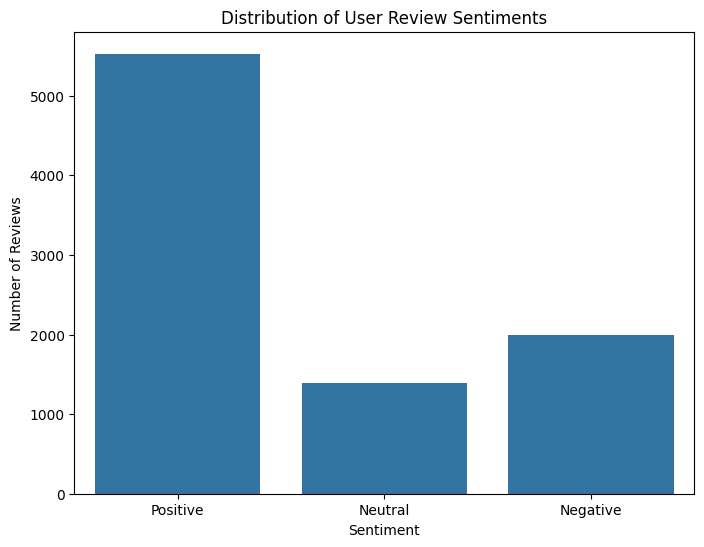

In [ ]:
plt.figure(figsize=(8,6))

sns.countplot(
    data=user_reviews,
    x='Sentiment'
)

plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.title('Distribution of User Review Sentiments')

plt.show()

Sentiment Percentage

In [ ]:
sentiment_percentage = (
    user_reviews['Sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

sentiment_percentage

,proportion
Sentiment,
Positive,62.00
Negative,22.40
Neutral,15.59


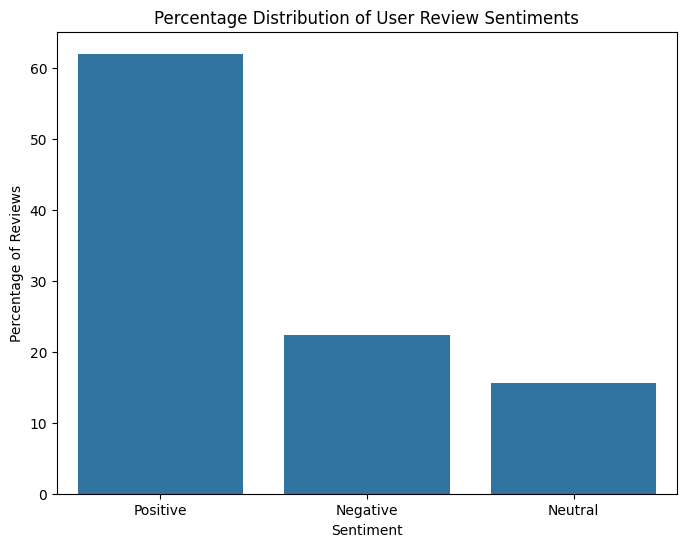

In [ ]:
plt.figure(figsize=(8,6))

sns.barplot(
    x=sentiment_percentage.index,
    y=sentiment_percentage.values
)

plt.xlabel('Sentiment')
plt.ylabel('Percentage of Reviews')
plt.title('Percentage Distribution of User Review Sentiments')

plt.show()

Sentiment Polarity Distribution

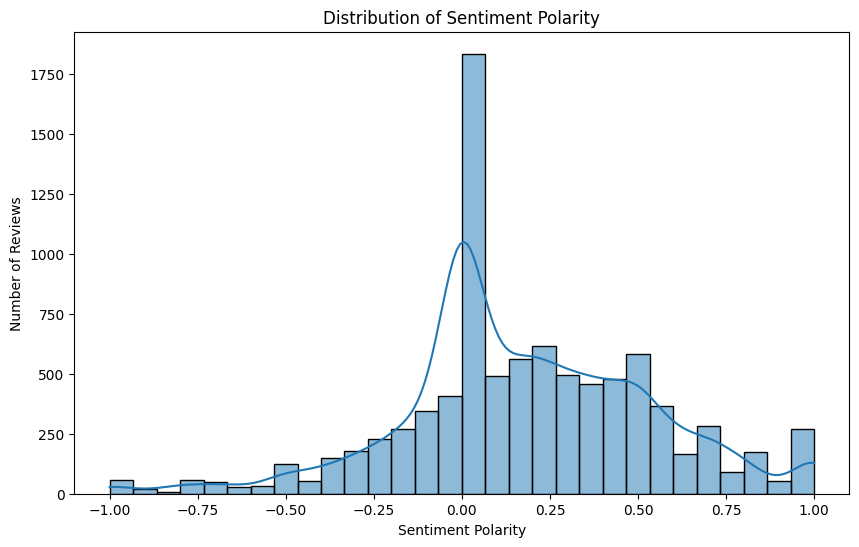

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=user_reviews,
    x='Sentiment_Polarity',
    bins=30,
    kde=True
)

plt.xlabel('Sentiment Polarity')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Sentiment Polarity')

plt.show()

Sentiment Polarity vs Subjectivity

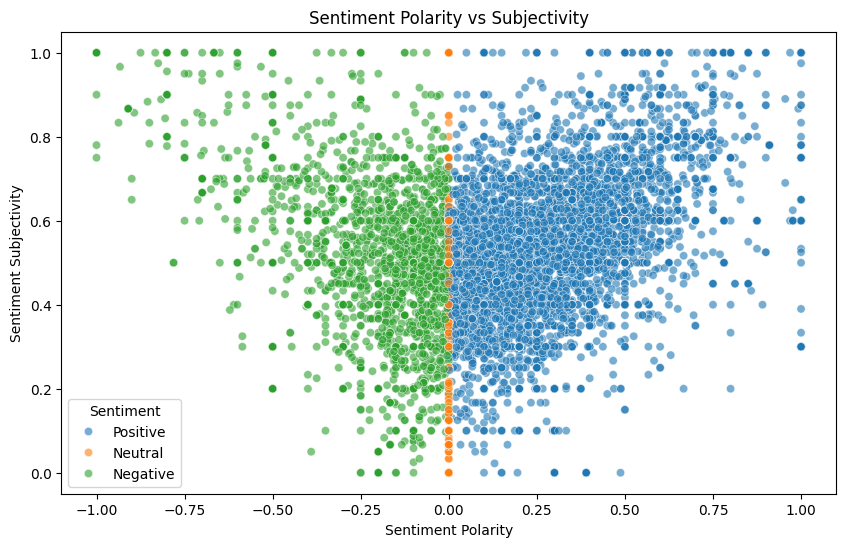

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=user_reviews,
    x='Sentiment_Polarity',
    y='Sentiment_Subjectivity',
    hue='Sentiment',
    alpha=0.6
)

plt.xlabel('Sentiment Polarity')
plt.ylabel('Sentiment Subjectivity')
plt.title('Sentiment Polarity vs Subjectivity')

plt.show()

App-Level Sentiment Analysis

In [ ]:
app_sentiment = (
    user_reviews
    .groupby(['App', 'Sentiment'])
    .size()
    .unstack(fill_value=0)
)

app_sentiment.head()

Sentiment,Negative,Neutral,Positive
App,,,
10 Best Foods for You,5,11,79
104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,1,8,27
11st,7,10,23
1800 Contacts - Lens Store,3,5,32
1LINE – One Line with One Touch,8,3,27


Positive / Negative Review Percentage

In [ ]:
app_sentiment['Total_Reviews'] = app_sentiment.sum(axis=1)

app_sentiment['Positive_%'] = (
    app_sentiment['Positive'] /
    app_sentiment['Total_Reviews'] * 100
)

app_sentiment['Negative_%'] = (
    app_sentiment['Negative'] /
    app_sentiment['Total_Reviews'] * 100
)

app_sentiment['Neutral_%'] = (
    app_sentiment['Neutral'] /
    app_sentiment['Total_Reviews'] * 100
)

app_sentiment = app_sentiment.round(2)

app_sentiment.head()

Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
App,,,,,,,
10 Best Foods for You,5,11,79,95,83.16,5.26,11.58
104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,1,8,27,36,75.00,2.78,22.22
11st,7,10,23,40,57.50,17.50,25.00
1800 Contacts - Lens Store,3,5,32,40,80.00,7.50,12.50
1LINE – One Line with One Touch,8,3,27,38,71.05,21.05,7.89


Top Apps by Positive Sentiment

In [ ]:
top_positive_apps = (
    app_sentiment
    .sort_values('Positive_%', ascending=False)
    .head(10)
)

top_positive_apps

Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
App,,,,,,,
Apartment Decorating Ideas,0,0,1,1,100.00,0.00,0.0
All-in-One Mahjong 3 FREE,0,0,1,1,100.00,0.00,0.0
Baby Panda’s Juice Shop,0,0,3,3,100.00,0.00,0.0
Best Fiends - Free Puzzle Game,0,0,1,1,100.00,0.00,0.0
Bed Time Fan - White Noise Sleep Sounds,0,0,1,1,100.00,0.00,0.0
Best Ovulation Tracker Fertility Calendar App Glow,0,0,1,1,100.00,0.00,0.0
7 Day Food Journal Challenge,0,0,9,9,100.00,0.00,0.0
Amazon Prime Video,0,0,2,2,100.00,0.00,0.0
3D Live Neon Weed Launcher,0,0,2,2,100.00,0.00,0.0


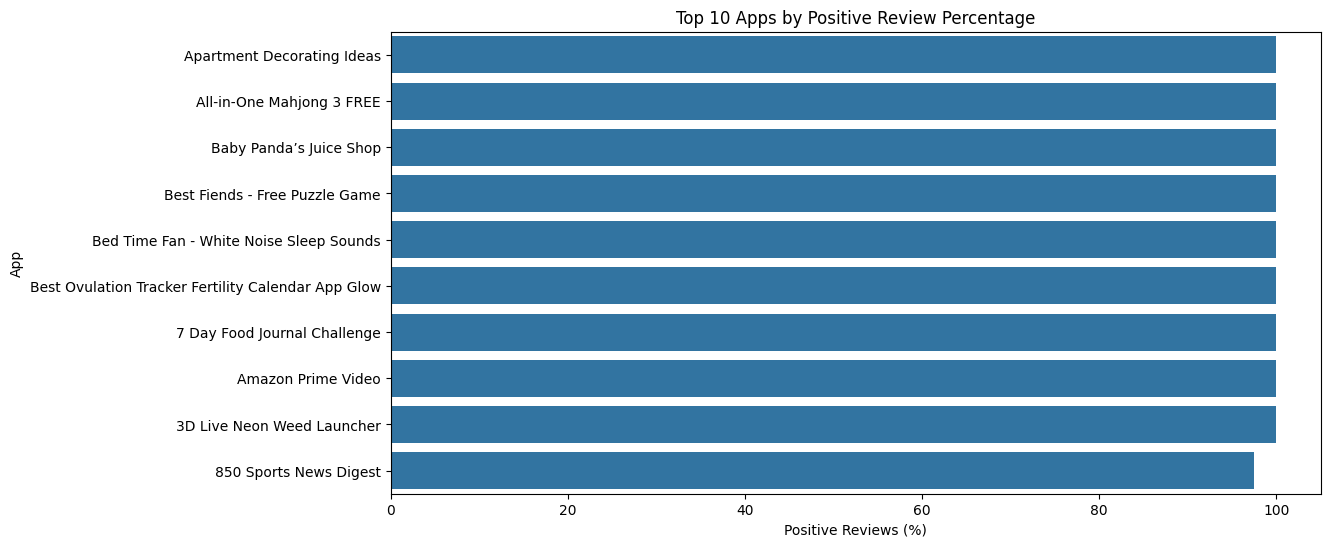

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_positive_apps.reset_index(),
    x='Positive_%',
    y='App'
)

plt.xlabel('Positive Reviews (%)')
plt.ylabel('App')
plt.title('Top 10 Apps by Positive Review Percentage')

plt.show()

Top Apps by Negative Sentiment

In [ ]:
top_negative_apps = (
    app_sentiment
    .sort_values('Negative_%', ascending=False)
    .head(10)
)

top_negative_apps

Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_%,Negative_%,Neutral_%
App,,,,,,,
Be A Legend: Soccer,59,6,33,98,33.67,60.20,6.12
Angry Birds Classic,59,1,47,107,43.93,55.14,0.93
Account Manager,18,4,11,33,33.33,54.55,12.12
AppLock,7,0,6,13,46.15,53.85,0.00
Blossom Blast Saga,19,0,17,36,47.22,52.78,0.00
Bancomer móvil,21,8,11,40,27.50,52.50,20.00
Angry Birds Rio,16,1,14,31,45.16,51.61,3.23
Baseball Boy!,20,0,20,40,50.00,50.00,0.00
All Social Networks,17,5,12,34,35.29,50.00,14.71


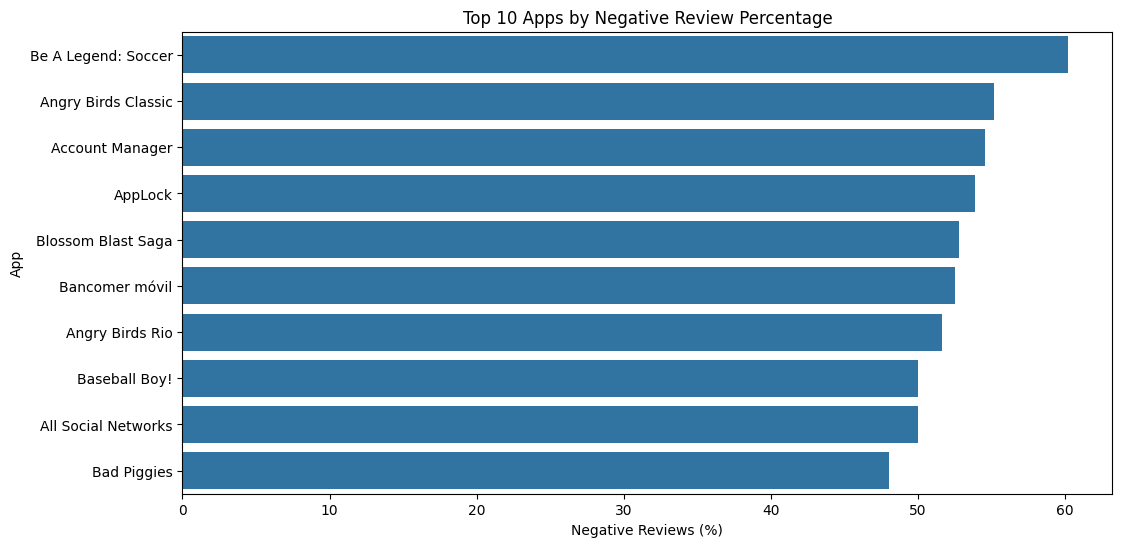

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_negative_apps.reset_index(),
    x='Negative_%',
    y='App'
)

plt.xlabel('Negative Reviews (%)')
plt.ylabel('App')
plt.title('Top 10 Apps by Negative Review Percentage')

plt.show()

Average Sentiment Polarity by App

In [ ]:
app_polarity = (
    user_reviews
    .groupby('App')['Sentiment_Polarity']
    .mean()
    .sort_values(ascending=False)
)

app_polarity.head(10)

,Sentiment_Polarity
App,
Bed Time Fan - White Noise Sleep Sounds,0.781250
Best Ovulation Tracker Fertility Calendar App Glow,0.595313
3D Live Neon Weed Launcher,0.568182
850 Sports News Digest,0.542860
"All Football GO- Live Score, Games",0.526515
BBVA Spain,0.506182
All Events in City,0.502860
All-in-One Mahjong 3 FREE,0.500000
ASUS Sound Recorder,0.497738


Lowest sentiment

In [ ]:
app_polarity.tail(10)

,Sentiment_Polarity
App,
"Bleacher Report: sports news, scores, & highlights",NaN
"Blendr - Chat, Flirt & Meet",NaN
Blibli.com Belanja Online,NaN
Blidz - Hunt Free Deals On Trending Items!,NaN
Blinkist - Nonfiction Books,NaN
Blitzer.de,NaN
Block Craft 3D: Building Simulator Games For Free,NaN
Blue CareOnDemand,NaN
BlueJeans for Android,NaN


NOW Merge Both Datasets

In [ ]:
merged_data = pd.merge(
    play_store,
    user_reviews,
    on='App',
    how='inner'
)

In [ ]:
merged_data.shape

(12280, 19)

In [ ]:
merged_data.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews_log,Installs_log,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,3D Color Pixel by Number - Sandbox Art Coloring,ART_AND_DESIGN,4.4,1518.0,37.0,100000.0,Free,0.0,Everyone,Art & Design,2018-08-03,1.2.3,2.3 and up,7.325808,11.512935,NaN,NaN,NaN,NaN
1,Animated Photo Editor,ART_AND_DESIGN,4.1,203.0,6.1,100000.0,Free,0.0,Everyone,Art & Design,2018-03-21,1.03,4.0.3 and up,5.318120,11.512935,This awesome app. Love it. Wish stickers thoug...,Positive,0.766667,0.783333
2,Animated Photo Editor,ART_AND_DESIGN,4.1,203.0,6.1,100000.0,Free,0.0,Everyone,Art & Design,2018-03-21,1.03,4.0.3 and up,5.318120,11.512935,Awesome absolutely love,Positive,0.750000,0.800000
3,Animated Photo Editor,ART_AND_DESIGN,4.1,203.0,6.1,100000.0,Free,0.0,Everyone,Art & Design,2018-03-21,1.03,4.0.3 and up,5.318120,11.512935,Very good work nicely,Positive,0.755000,0.890000
4,Animated Photo Editor,ART_AND_DESIGN,4.1,203.0,6.1,100000.0,Free,0.0,Everyone,Art & Design,2018-03-21,1.03,4.0.3 and up,5.318120,11.512935,So nice,Positive,0.600000,1.000000


Rating vs Review Sentiment

In [ ]:
rating_sentiment = (
    merged_data
    .groupby('Rating')['Sentiment_Polarity']
    .mean()
    .reset_index()
)

rating_sentiment

,Rating,Sentiment_Polarity
0,2.6,-0.123233
1,2.7,-0.062826
2,3.0,0.086058
3,3.1,0.233333
4,3.3,NaN
5,3.4,0.043629
6,3.5,0.137703
7,3.6,0.071301
8,3.7,0.061899
9,3.8,0.078542


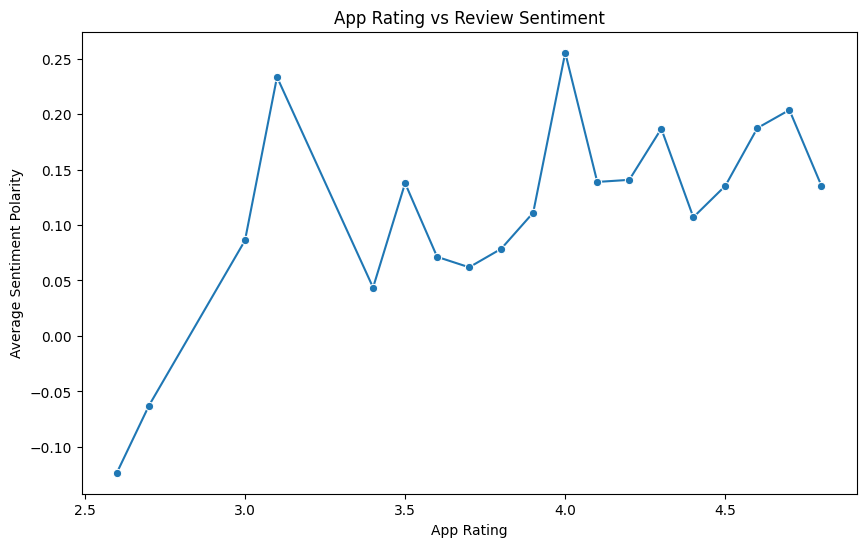

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=rating_sentiment,
    x='Rating',
    y='Sentiment_Polarity',
    marker='o'
)

plt.xlabel('App Rating')
plt.ylabel('Average Sentiment Polarity')
plt.title('App Rating vs Review Sentiment')

plt.show()

Category vs Review Sentiment

In [ ]:
category_sentiment = (
    merged_data
    .groupby('Category')['Sentiment_Polarity']
    .mean()
    .sort_values(ascending=False)
)

category_sentiment

,Sentiment_Polarity
Category,
EVENTS,0.502860
FOOD_AND_DRINK,0.365780
HEALTH_AND_FITNESS,0.326876
VIDEO_PLAYERS,0.323360
AUTO_AND_VEHICLES,0.317155
ART_AND_DESIGN,0.308400
COMICS,0.300429
EDUCATION,0.297645
BUSINESS,0.292761


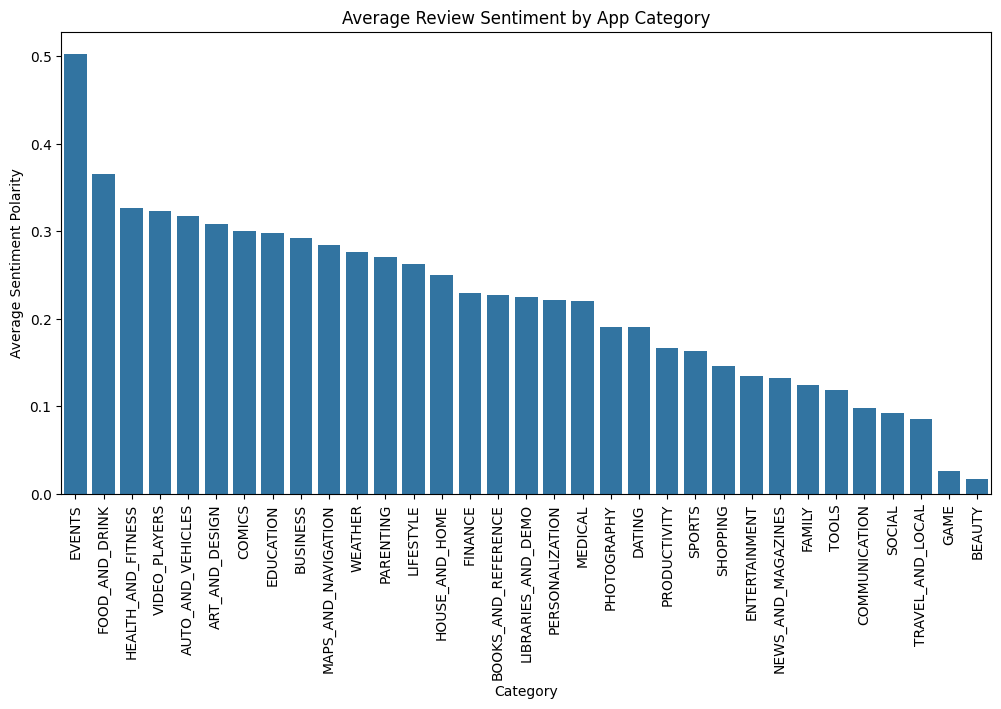

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=category_sentiment.index,
    y=category_sentiment.values
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Sentiment Polarity')
plt.title('Average Review Sentiment by App Category')

plt.show()

FINAL Combined Category Analysis

In [ ]:
final_analysis = (
    merged_data
    .groupby('Category')
    .agg(
        Apps=('App', 'nunique'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean'),
        Avg_Sentiment=('Sentiment_Polarity', 'mean')
    )
    .reset_index()
)

final_analysis = final_analysis.round(2)

final_analysis

,Category,Apps,Avg_Rating,Avg_Reviews,Avg_Installs,Avg_Sentiment
0,ART_AND_DESIGN,3,4.27,2238.25,100000.00,0.31
1,AUTO_AND_VEHICLES,4,4.38,85850.13,3355140.19,0.32
2,BEAUTY,3,3.93,35983.61,3404958.68,0.02
3,BOOKS_AND_REFERENCE,7,4.35,882088.62,63080091.53,0.23
4,BUSINESS,5,4.30,10364.84,710091.74,0.29
5,COMICS,1,4.70,3596.00,10000.00,0.30
6,COMMUNICATION,6,4.18,3854665.97,56977443.61,0.10
7,DATING,13,4.07,7623.31,470153.17,0.19
8,EDUCATION,4,4.20,149653.17,6306666.67,0.30
9,ENTERTAINMENT,8,3.84,35276.19,3240816.33,0.13


Aggregate user_reviews by App

In [ ]:
review_summary = (
    user_reviews
    .groupby('App')
    .agg(
        Avg_Sentiment=('Sentiment_Polarity', 'mean'),
        Avg_Subjectivity=('Sentiment_Subjectivity', 'mean'),
        Positive_Reviews=('Sentiment', lambda x: (x == 'Positive').sum()),
        Negative_Reviews=('Sentiment', lambda x: (x == 'Negative').sum()),
        Neutral_Reviews=('Sentiment', lambda x: (x == 'Neutral').sum()),
        Total_User_Reviews=('Sentiment', 'count')
    )
    .reset_index()
)

review_summary.head()

,App,Avg_Sentiment,Avg_Subjectivity,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Total_User_Reviews
0,10 Best Foods for You,0.465906,0.493254,79,5,11,95
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,0.358227,0.508907,27,1,8,36
2,11st,0.181294,0.443957,23,7,10,40
3,1800 Contacts - Lens Store,0.318145,0.591098,32,3,5,40
4,1LINE – One Line with One Touch,0.196290,0.557315,27,8,3,38


Calculate Sentiment Percentages

In [ ]:
review_summary['Positive_%'] = (
    review_summary['Positive_Reviews'] /
    review_summary['Total_User_Reviews'] * 100
)

review_summary['Negative_%'] = (
    review_summary['Negative_Reviews'] /
    review_summary['Total_User_Reviews'] * 100
)

review_summary['Neutral_%'] = (
    review_summary['Neutral_Reviews'] /
    review_summary['Total_User_Reviews'] * 100
)

review_summary = review_summary.round(2)

review_summary.head()

,App,Avg_Sentiment,Avg_Subjectivity,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Total_User_Reviews,Positive_%,Negative_%,Neutral_%
0,10 Best Foods for You,0.47,0.49,79,5,11,95,83.16,5.26,11.58
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,0.36,0.51,27,1,8,36,75.00,2.78,22.22
2,11st,0.18,0.44,23,7,10,40,57.50,17.50,25.00
3,1800 Contacts - Lens Store,0.32,0.59,32,3,5,40,80.00,7.50,12.50
4,1LINE – One Line with One Touch,0.20,0.56,27,8,3,38,71.05,21.05,7.89


Merge With play_store

In [ ]:
app_level_analysis = pd.merge(
    play_store,
    review_summary,
    on='App',
    how='inner'
)

app_level_analysis.shape

(345, 24)

In [ ]:
app_level_analysis.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,...,Installs_log,Avg_Sentiment,Avg_Subjectivity,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Total_User_Reviews,Positive_%,Negative_%,Neutral_%
0,3D Color Pixel by Number - Sandbox Art Coloring,ART_AND_DESIGN,4.4,1518.0,37.0,100000.0,Free,0.0,Everyone,Art & Design,...,11.512935,NaN,NaN,0,0,0,0,NaN,NaN,NaN
1,Animated Photo Editor,ART_AND_DESIGN,4.1,203.0,6.1,100000.0,Free,0.0,Everyone,Art & Design,...,11.512935,0.27,0.53,19,4,10,33,57.58,12.12,30.30
2,Anime Manga Coloring Book,ART_AND_DESIGN,4.5,5035.0,11.0,100000.0,Free,0.0,Everyone,Art & Design,...,11.512935,0.36,0.51,19,3,2,24,79.17,12.50,8.33
3,"Android Auto - Maps, Media, Messaging & Voice",AUTO_AND_VEHICLES,4.2,271920.0,16.0,10000000.0,Free,0.0,Teen,Auto & Vehicles,...,16.118096,0.29,0.54,30,1,0,31,96.77,3.23,0.00
4,Best Car Wallpapers,AUTO_AND_VEHICLES,4.5,994.0,2.9,100000.0,Free,0.0,Everyone,Auto & Vehicles,...,11.512935,-0.13,0.49,1,1,1,3,33.33,33.33,33.33


Create Final Category-Level Analysis

Now we'll combine:

App count
Rating
Reviews
Installs
Sentiment
Positive reviews
Negative reviews

In [ ]:
category_app_metrics = (
    play_store
    .groupby('Category')
    .agg(
        Apps=('App', 'nunique'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean')
    )
    .reset_index()
)

category_review_metrics = (
    user_reviews
    .merge(
        play_store[['App', 'Category']],
        on='App',
        how='inner'
    )
    .groupby('Category')
    .agg(
        Total_User_Reviews=('Sentiment', 'count'),
        Avg_Sentiment=('Sentiment_Polarity', 'mean'),
        Positive_Reviews=('Sentiment', lambda x: (x == 'Positive').sum()),
        Negative_Reviews=('Sentiment', lambda x: (x == 'Negative').sum()),
        Neutral_Reviews=('Sentiment', lambda x: (x == 'Neutral').sum())
    )
    .reset_index()
)

category_review_metrics['Positive_%'] = (
    category_review_metrics['Positive_Reviews'] /
    category_review_metrics['Total_User_Reviews'] * 100
)

category_review_metrics['Negative_%'] = (
    category_review_metrics['Negative_Reviews'] /
    category_review_metrics['Total_User_Reviews'] * 100
)

final_category = pd.merge(
    category_app_metrics,
    category_review_metrics,
    on='Category',
    how='left'
)

final_category = final_category.round(2)

final_category

,Category,Apps,Avg_Rating,Avg_Reviews,Avg_Installs,Total_User_Reviews,Avg_Sentiment,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_%,Negative_%
0,ART_AND_DESIGN,61,4.36,27651.16,2003759.68,57,0.31,38,7,12,66.67,12.28
1,AUTO_AND_VEHICLES,73,4.19,15940.14,727805.48,103,0.32,81,8,14,78.64,7.77
2,BEAUTY,42,4.28,9407.93,640861.90,118,0.02,43,35,40,36.44,29.66
3,BOOKS_AND_REFERENCE,169,4.35,123575.24,10826506.53,429,0.23,290,66,73,67.60,15.38
4,BUSINESS,263,4.10,45769.28,3198215.26,104,0.29,69,8,27,66.35,7.69
5,COMICS,54,4.16,58309.40,966139.66,10,0.30,6,0,4,60.00,0.00
6,COMMUNICATION,257,4.15,1958544.27,78671796.51,260,0.10,119,70,71,45.77,26.92
7,DATING,134,3.97,34875.25,1298883.08,443,0.19,277,87,79,62.53,19.64
8,EDUCATION,118,4.38,179571.50,4138387.60,145,0.30,102,17,26,70.34,11.72
9,ENTERTAINMENT,102,4.14,428565.01,22123063.06,139,0.13,80,35,24,57.55,25.18


This final_category table is going to be one of the most important outputs of the entire project because it connects the Play Store data with customer sentiment.

Visualize Category vs Sentiment

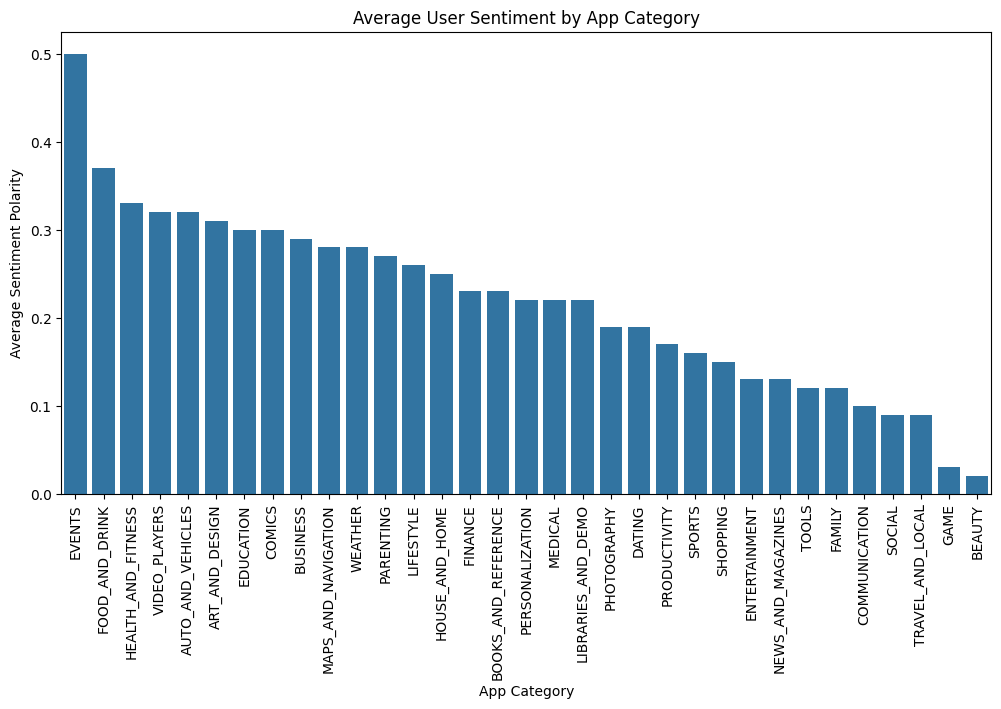

In [ ]:
category_sentiment = (
    final_category
    .sort_values('Avg_Sentiment', ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_sentiment,
    x='Category',
    y='Avg_Sentiment'
)

plt.xticks(rotation=90)
plt.xlabel('App Category')
plt.ylabel('Average Sentiment Polarity')
plt.title('Average User Sentiment by App Category')
plt.show()

Visualize Installs vs Sentiment

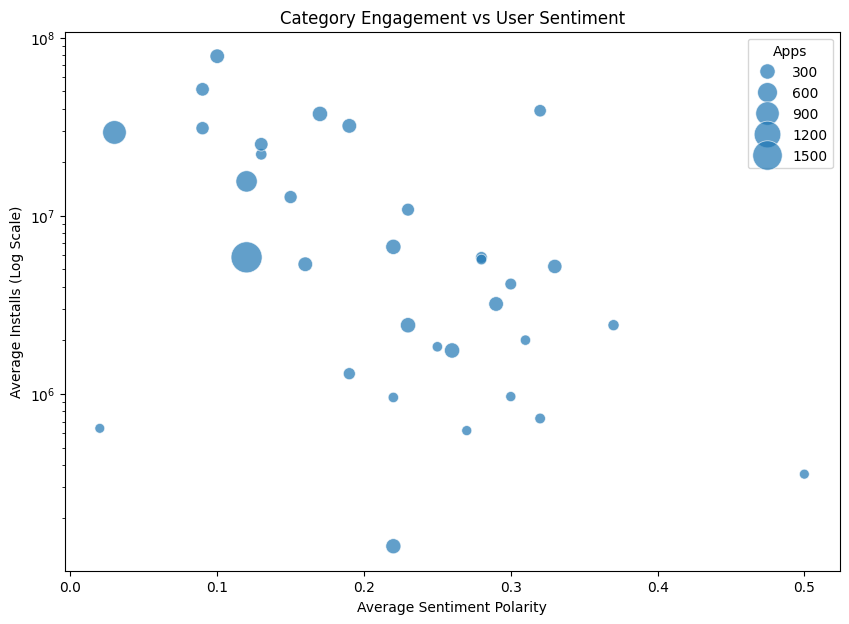

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=final_category,
    x='Avg_Sentiment',
    y='Avg_Installs',
    size='Apps',
    sizes=(50, 500),
    alpha=0.7
)

plt.yscale('log')

plt.xlabel('Average Sentiment Polarity')
plt.ylabel('Average Installs (Log Scale)')
plt.title('Category Engagement vs User Sentiment')
plt.show()

| Category position                  | Business meaning                      |
| ---------------------------------- | ------------------------------------- |
| High installs + Positive sentiment | ⭐ Strong opportunity                  |
| High installs + Negative sentiment | ⚠️ Large market but customer problems |
| Low installs + Positive sentiment  | 📈 Potential growth opportunity       |
| Low installs + Negative sentiment  | 🔻 Lower priority                     |


Create the Opportunity Classification

In [ ]:
median_installs = final_category['Avg_Installs'].median()
median_sentiment = final_category['Avg_Sentiment'].median()

final_category['Opportunity'] = np.select(
    [
        (final_category['Avg_Installs'] >= median_installs) &
        (final_category['Avg_Sentiment'] >= median_sentiment),

        (final_category['Avg_Installs'] >= median_installs) &
        (final_category['Avg_Sentiment'] < median_sentiment),

        (final_category['Avg_Installs'] < median_installs) &
        (final_category['Avg_Sentiment'] >= median_sentiment),

        (final_category['Avg_Installs'] < median_installs) &
        (final_category['Avg_Sentiment'] < median_sentiment)
    ],
    [
        'High Reach + Positive Sentiment',
        'High Reach + Low Sentiment',
        'Low Reach + Positive Sentiment',
        'Low Reach + Low Sentiment'
    ],
    default='Unclassified' # Added a default string value
)

final_category[
    ['Category', 'Avg_Installs', 'Avg_Sentiment', 'Opportunity']
].sort_values('Avg_Installs', ascending=False)

,Category,Avg_Installs,Avg_Sentiment,Opportunity
6,COMMUNICATION,78671796.51,0.10,High Reach + Low Sentiment
27,SOCIAL,51286235.55,0.09,High Reach + Low Sentiment
31,VIDEO_PLAYERS,38886857.50,0.32,High Reach + Positive Sentiment
25,PRODUCTIVITY,37314581.38,0.17,High Reach + Low Sentiment
24,PHOTOGRAPHY,31977773.45,0.19,High Reach + Low Sentiment
30,TRAVEL_AND_LOCAL,31033460.00,0.09,High Reach + Low Sentiment
14,GAME,29370449.46,0.03,High Reach + Low Sentiment
21,NEWS_AND_MAGAZINES,25201451.64,0.13,High Reach + Low Sentiment
9,ENTERTAINMENT,22123063.06,0.13,High Reach + Low Sentiment
29,TOOLS,15600442.10,0.12,High Reach + Low Sentiment


Identify the Most Reviewed Apps

In [ ]:
top_reviewed_apps = (
    play_store[['App', 'Reviews', 'Rating', 'Installs', 'Category']]
    .sort_values('Reviews', ascending=False)
    .head(10)
)

top_reviewed_apps

,App,Reviews,Rating,Installs,Category
2544,Facebook,78158306.0,4.1,1.000000e+09,SOCIAL
3943,Facebook,78128208.0,4.1,1.000000e+09,SOCIAL
336,WhatsApp Messenger,69119316.0,4.4,1.000000e+09,COMMUNICATION
3904,WhatsApp Messenger,69109672.0,4.4,1.000000e+09,COMMUNICATION
2604,Instagram,66577446.0,4.5,1.000000e+09,SOCIAL
2545,Instagram,66577313.0,4.5,1.000000e+09,SOCIAL
3909,Instagram,66509917.0,4.5,1.000000e+09,SOCIAL
382,Messenger – Text and Video Chat for Free,56646578.0,4.0,1.000000e+09,COMMUNICATION
335,Messenger – Text and Video Chat for Free,56642847.0,4.0,1.000000e+09,COMMUNICATION
1879,Clash of Clans,44893888.0,4.6,1.000000e+08,GAME


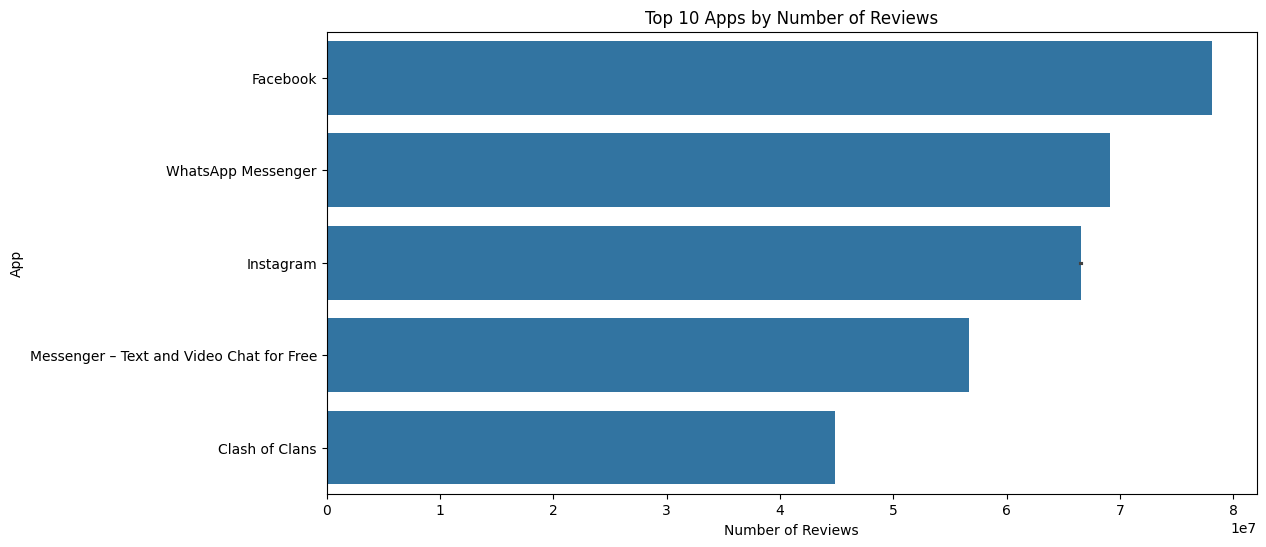

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_reviewed_apps,
    x='Reviews',
    y='App'
)

plt.xlabel('Number of Reviews')
plt.ylabel('App')
plt.title('Top 10 Apps by Number of Reviews')

plt.show()

Apps with very high review counts have achieved substantial user interaction. However, high reviews alone don't mean users are satisfied, so we'll combine this with sentiment.

Top Apps by Installs

In [ ]:
top_installed_apps = (
    play_store[['App', 'Installs', 'Rating', 'Reviews', 'Category']]
    .sort_values('Installs', ascending=False)
    .head(10)
)

top_installed_apps

,App,Installs,Rating,Reviews,Category
3896,Subway Surfers,1.000000e+09,4.5,27711703.0,GAME
4153,Hangouts,1.000000e+09,4.0,3419464.0,COMMUNICATION
4150,Google,1.000000e+09,4.4,8021623.0,TOOLS
3904,WhatsApp Messenger,1.000000e+09,4.4,69109672.0,COMMUNICATION
3816,Google News,1.000000e+09,3.9,877643.0,NEWS_AND_MAGAZINES
3127,Google Street View,1.000000e+09,4.2,2129689.0,TRAVEL_AND_LOCAL
3909,Instagram,1.000000e+09,4.5,66509917.0,SOCIAL
1654,Subway Surfers,1.000000e+09,4.5,27722264.0,GAME
4144,Google+,1.000000e+09,4.2,4828372.0,SOCIAL
3523,Google Drive,1.000000e+09,4.4,2731211.0,PRODUCTIVITY


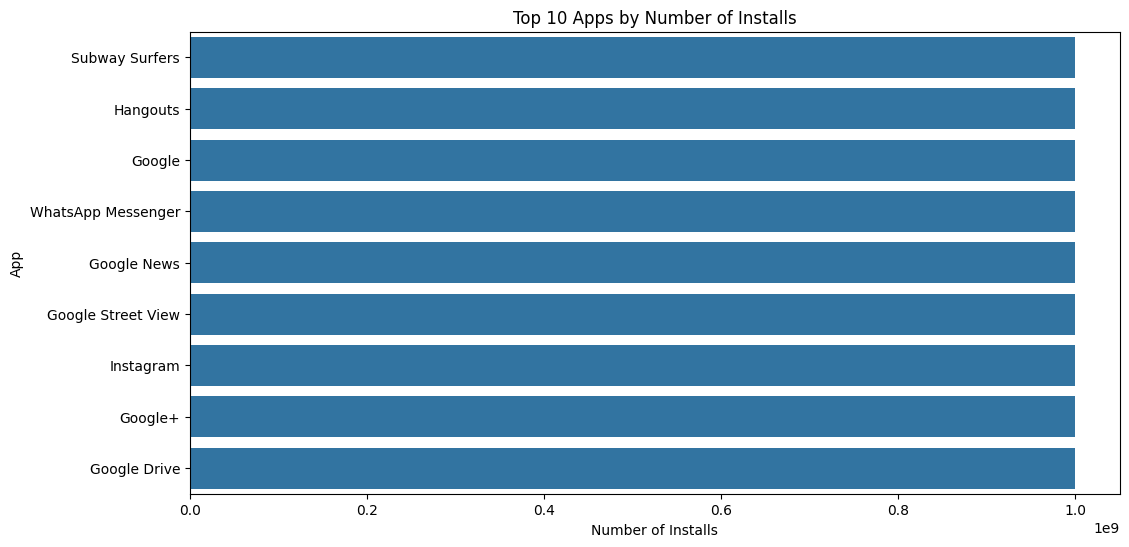

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_installed_apps,
    x='Installs',
    y='App'
)

plt.xlabel('Number of Installs')
plt.ylabel('App')
plt.title('Top 10 Apps by Number of Installs')

plt.show()

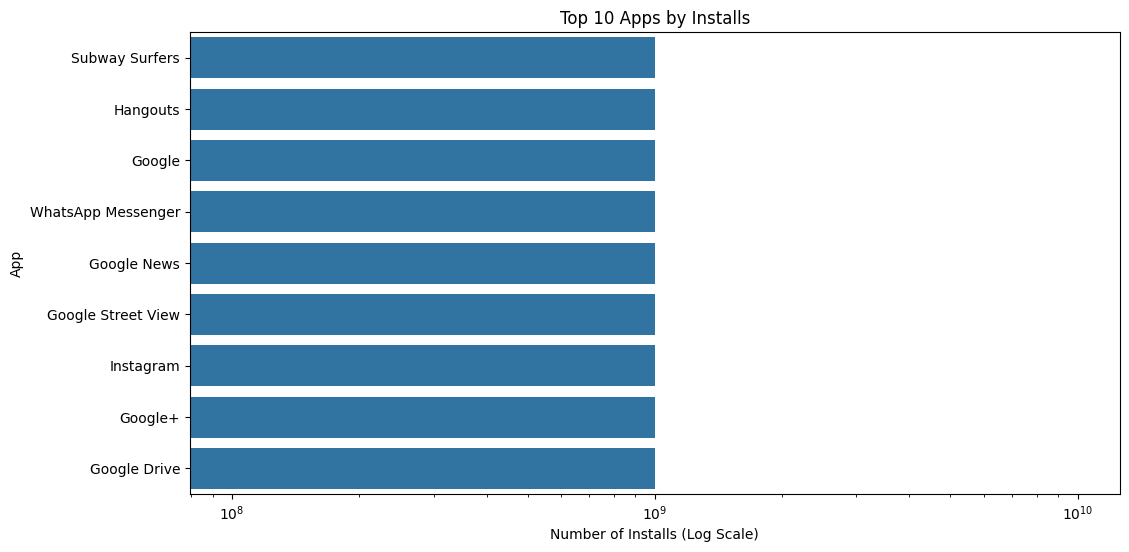

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_installed_apps,
    x='Installs',
    y='App'
)

plt.xscale('log')

plt.xlabel('Number of Installs (Log Scale)')
plt.ylabel('App')
plt.title('Top 10 Apps by Installs')

plt.show()

Connect Installs With Sentiment

In [ ]:
install_sentiment = (
    app_level_analysis[
        ['App', 'Category', 'Rating', 'Reviews', 'Installs',
         'Avg_Sentiment', 'Positive_%', 'Negative_%']
    ]
    .sort_values('Installs', ascending=False)
)

install_sentiment.head(10)

,App,Category,Rating,Reviews,Installs,Avg_Sentiment,Positive_%,Negative_%
10,Amazon Kindle,BOOKS_AND_REFERENCE,4.2,814080.0,100000000.0,0.08,54.65,25.58
333,BBM - Free Calls & Messages,COMMUNICATION,4.3,12843436.0,100000000.0,0.14,50.00,23.53
335,Badoo - Free Chat & Dating App,SOCIAL,4.3,3781467.0,100000000.0,0.15,50.00,21.43
266,Adobe Acrobat Reader,PRODUCTIVITY,4.3,3016305.0,100000000.0,0.15,68.37,20.41
22,Android Messages,COMMUNICATION,4.2,781810.0,100000000.0,0.07,56.25,34.38
24,BBM - Free Calls & Messages,COMMUNICATION,4.3,12842860.0,100000000.0,0.14,50.00,23.53
310,8 Ball Pool,SPORTS,4.5,14184910.0,100000000.0,0.01,50.00,47.92
312,Amazon Kindle,BOOKS_AND_REFERENCE,4.2,814151.0,100000000.0,0.08,54.65,25.58
250,Backgrounds HD (Wallpapers),PERSONALIZATION,4.6,2390185.0,100000000.0,0.34,58.62,10.34
256,Adobe Acrobat Reader,PRODUCTIVITY,4.3,3016297.0,100000000.0,0.15,68.37,20.41


Top Installed Apps With Their Sentiment

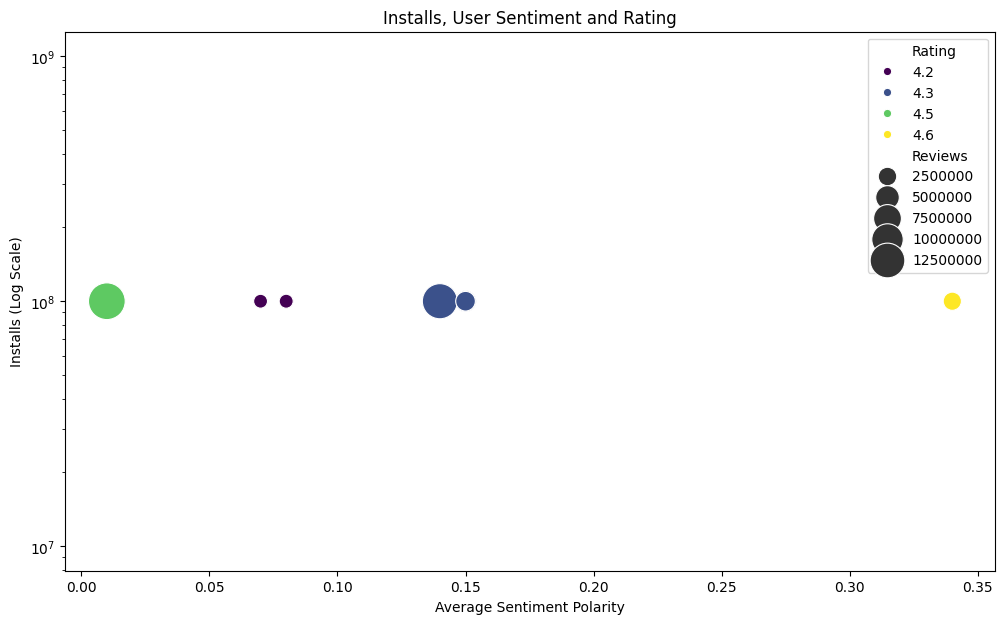

In [ ]:
top_10_install_sentiment = install_sentiment.head(10)

plt.figure(figsize=(12,7))

sns.scatterplot(
    data=top_10_install_sentiment,
    x='Avg_Sentiment',
    y='Installs',
    size='Reviews',
    sizes=(100, 700),
    hue='Rating',
    palette='viridis'
)

plt.yscale('log')

plt.xlabel('Average Sentiment Polarity')
plt.ylabel('Installs (Log Scale)')
plt.title('Installs, User Sentiment and Rating')

plt.show()

This visualization combines:

X → Sentiment
Y → Installs
Bubble size → Reviews
Color → Rating

This is a genuine multivariate visualization.

Find Apps With High Reach but Negative Sentiment

In [ ]:
high_reach_negative = app_level_analysis[
    (app_level_analysis['Installs'] >= app_level_analysis['Installs'].median()) &
    (app_level_analysis['Avg_Sentiment'] < 0)
]

high_reach_negative[
    ['App', 'Category', 'Installs', 'Rating', 'Avg_Sentiment',
     'Positive_%', 'Negative_%']
].sort_values(
    'Installs',
    ascending=False
).head(15)

,App,Category,Installs,Rating,Avg_Sentiment,Positive_%,Negative_%
111,Angry Birds Rio,GAME,100000000.0,4.4,-0.01,45.16,51.61
114,Angry Birds Classic,GAME,100000000.0,4.4,-0.02,43.93,55.14
119,Angry Birds Rio,GAME,100000000.0,4.4,-0.01,45.16,51.61
297,Angry Birds Classic,GAME,100000000.0,4.4,-0.02,43.93,55.14
120,Angry Birds Classic,GAME,100000000.0,4.4,-0.02,43.93,55.14
130,Angry Birds Classic,GAME,100000000.0,4.4,-0.02,43.93,55.14
134,Agar.io,GAME,100000000.0,4.2,-0.05,44.68,46.81
140,Angry Birds Rio,GAME,100000000.0,4.4,-0.01,45.16,51.61
141,Angry Birds Classic,GAME,100000000.0,4.4,-0.02,43.93,55.14
316,Angry Birds Rio,GAME,100000000.0,4.4,-0.01,45.16,51.61


Find Apps With Positive Sentiment but Lower Reach

In [ ]:
growth_opportunities = app_level_analysis[
    (app_level_analysis['Installs'] < app_level_analysis['Installs'].median()) &
    (app_level_analysis['Avg_Sentiment'] > 0)
]

growth_opportunities[
    ['App', 'Category', 'Installs', 'Rating',
     'Avg_Sentiment', 'Positive_%']
].sort_values(
    'Avg_Sentiment',
    ascending=False
).head(15)

,App,Category,Installs,Rating,Avg_Sentiment,Positive_%
108,Bed Time Fan - White Noise Sleep Sounds,LIFESTYLE,500000.0,4.5,0.78,100.00
82,Best Ovulation Tracker Fertility Calendar App ...,HEALTH_AND_FITNESS,1000000.0,4.6,0.60,100.00
238,3D Live Neon Weed Launcher,PERSONALIZATION,100000.0,4.5,0.57,100.00
214,850 Sports News Digest,SPORTS,10000.0,4.6,0.54,97.44
211,"All Football GO- Live Score, Games",SPORTS,100000.0,4.6,0.53,83.33
155,All-in-One Mahjong 3 FREE,FAMILY,50000.0,4.5,0.50,100.00
56,All Events in City,EVENTS,100000.0,4.0,0.50,92.00
84,10 Best Foods for You,HEALTH_AND_FITNESS,500000.0,4.0,0.47,83.16
88,"Apartment List: Housing, Apt, and Property Ren...",HOUSE_AND_HOME,1000000.0,4.5,0.44,87.10
19,Accounting App - Zoho Books,BUSINESS,100000.0,4.5,0.43,78.95


Calculate Correlations

In [ ]:
analysis_columns = [
    'Rating',
    'Reviews',
    'Installs',
    'Price',
    'Size',
    'Avg_Sentiment',
    'Positive_%',
    'Negative_%'
]

app_level_analysis[analysis_columns].corr().round(2)

,Rating,Reviews,Installs,Price,Size,Avg_Sentiment,Positive_%,Negative_%
Rating,1.00,0.20,0.23,-0.11,0.15,0.25,0.30,-0.13
Reviews,0.20,1.00,0.73,-0.03,0.39,-0.29,-0.23,0.39
Installs,0.23,0.73,1.00,-0.05,0.48,-0.32,-0.30,0.39
Price,-0.11,-0.03,-0.05,1.00,0.09,-0.00,0.02,-0.04
Size,0.15,0.39,0.48,0.09,1.00,-0.32,-0.25,0.39
Avg_Sentiment,0.25,-0.29,-0.32,-0.00,-0.32,1.00,0.78,-0.84
Positive_%,0.30,-0.23,-0.30,0.02,-0.25,0.78,1.00,-0.69
Negative_%,-0.13,0.39,0.39,-0.04,0.39,-0.84,-0.69,1.00


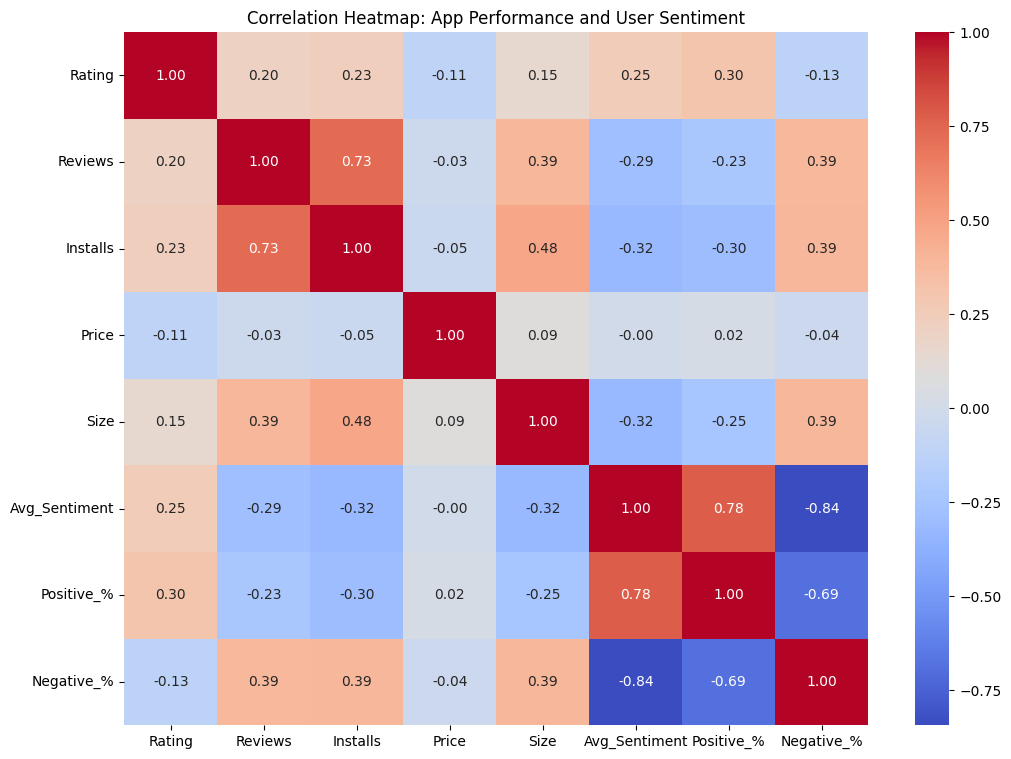

In [ ]:
plt.figure(figsize=(12,9))

sns.heatmap(
    app_level_analysis[analysis_columns].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap: App Performance and User Sentiment')

plt.show()

Create a Final App-Level Score

In [ ]:
from sklearn.preprocessing import MinMaxScaler

score_data = app_level_analysis[
    ['App', 'Rating', 'Installs', 'Avg_Sentiment']
].copy()

scaler = MinMaxScaler()

score_data[
    ['Rating_Score', 'Install_Score', 'Sentiment_Score']
] = scaler.fit_transform(
    score_data[
        ['Rating', 'Installs', 'Avg_Sentiment']
    ]
)

In [ ]:
score_data['Success_Score'] = (
    0.30 * score_data['Rating_Score'] +
    0.40 * score_data['Install_Score'] +
    0.30 * score_data['Sentiment_Score']
)

score_data = score_data.sort_values(
    'Success_Score',
    ascending=False
)

score_data.head(15)

,App,Rating,Installs,Avg_Sentiment,Rating_Score,Install_Score,Sentiment_Score,Success_Score
307,Bible,4.7,100000000.0,0.36,0.954545,1.0,0.538462,0.847902
243,"APUS Launcher - Theme, Wallpaper, Hide Apps",4.5,100000000.0,0.44,0.863636,1.0,0.626374,0.847003
250,Backgrounds HD (Wallpapers),4.6,100000000.0,0.34,0.909091,1.0,0.516484,0.827672
331,Backgrounds HD (Wallpapers),4.6,100000000.0,0.34,0.909091,1.0,0.516484,0.827672
206,BeautyPlus - Easy Photo Editor & Selfie Camera,4.4,100000000.0,0.30,0.818182,1.0,0.472527,0.787213
202,BeautyPlus - Easy Photo Editor & Selfie Camera,4.4,100000000.0,0.30,0.818182,1.0,0.472527,0.787213
329,BeautyPlus - Easy Photo Editor & Selfie Camera,4.4,100000000.0,0.30,0.818182,1.0,0.472527,0.787213
197,BeautyPlus - Easy Photo Editor & Selfie Camera,4.4,100000000.0,0.30,0.818182,1.0,0.472527,0.787213
303,Amazon Shopping,4.3,100000000.0,0.19,0.772727,1.0,0.351648,0.737313
186,Amazon Shopping,4.3,100000000.0,0.19,0.772727,1.0,0.351648,0.737313


This is not an official industry success metric.

It's an EDA-derived analytical score that we created to compare apps using multiple dimensions.

"I normalized rating, installations and review sentiment because they have different scales, then created a weighted composite score to compare apps across satisfaction, reach and user sentiment."

Top Performing Categories

In [ ]:
score_with_category = pd.merge(
    score_data[['App', 'Success_Score']],
    play_store[['App', 'Category']],
    on='App',
    how='left'
)

category_success = (
    score_with_category
    .groupby('Category')['Success_Score']
    .mean()
    .sort_values(ascending=False)
)

category_success

,Success_Score
Category,
PHOTOGRAPHY,0.649534
SHOPPING,0.635173
GAME,0.597456
COMMUNICATION,0.548444
BOOKS_AND_REFERENCE,0.547780
WEATHER,0.530681
PRODUCTIVITY,0.514086
SPORTS,0.505586
FOOD_AND_DRINK,0.445324


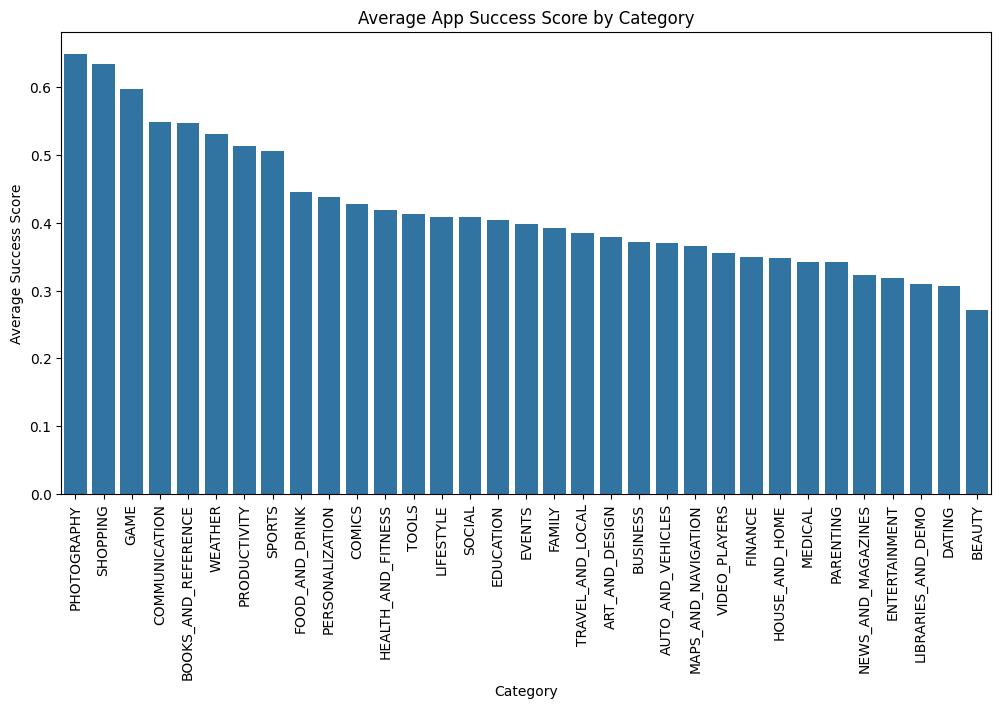

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=category_success.index,
    y=category_success.values
)

plt.xticks(rotation=90)
plt.xlabel('Category')
plt.ylabel('Average Success Score')
plt.title('Average App Success Score by Category')

plt.show()

Final Business Insight Table

In [ ]:
final_business_table = (
    app_level_analysis
    .groupby('Category')
    .agg(
        Apps=('App', 'nunique'),
        Avg_Rating=('Rating', 'mean'),
        Avg_Reviews=('Reviews', 'mean'),
        Avg_Installs=('Installs', 'mean'),
        Avg_Sentiment=('Avg_Sentiment', 'mean'),
        Avg_Positive_Percentage=('Positive_%', 'mean'),
        Avg_Negative_Percentage=('Negative_%', 'mean')
    )
    .reset_index()
)

final_business_table.round(2)

,Category,Apps,Avg_Rating,Avg_Reviews,Avg_Installs,Avg_Sentiment,Avg_Positive_Percentage,Avg_Negative_Percentage
0,ART_AND_DESIGN,3,4.33,2252.00,100000.00,0.32,68.38,12.31
1,AUTO_AND_VEHICLES,4,4.40,71658.50,2800000.00,0.21,68.80,13.49
2,BEAUTY,3,4.03,39226.33,3666666.67,0.07,44.14,27.58
3,BOOKS_AND_REFERENCE,7,4.29,532109.62,39062500.00,0.25,69.15,13.13
4,BUSINESS,5,4.22,23457.20,1520000.00,0.29,66.41,7.76
5,COMICS,1,4.70,3596.00,10000.00,0.30,60.00,0.00
6,COMMUNICATION,6,4.14,3944426.43,51714285.71,0.12,48.96,28.96
7,DATING,13,4.02,7757.38,473125.00,0.19,62.70,19.39
8,EDUCATION,4,4.18,126471.20,5400000.00,0.30,70.06,11.62
9,ENTERTAINMENT,8,3.95,74997.88,8018750.00,0.18,67.29,20.87
